<a href="https://colab.research.google.com/github/Badreddiine/Application-de-devsecops-dans-projet-/blob/main/TP4_EL_ABBADY_Badr_Eddine_SecureAgent_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP 4 : Développement logiciel augmenté par des agents IA

**Nom :** EL ABBADY  
**Prénom :** Badr Eddine  
**Filière :** Génie Informatique : FST Settat



Construire une application **Spring Boot / JEE** de A à Z avec une équipe d'agents spécialisés. **Langages :** Python 3.10+ (notebook) et Java 21 (projet)

### Objectif du projet


Vous allez concevoir un système de **plusieurs agents logiciels** qui assistent un développeur dans toutes les phases du cycle de vie d'une application Java/Spring Boot :

```
Besoin → Analyse → Architecture → Code → Tests → Qualité → Conteneurisation → CI/CD → Documentation
```

L'objectif **n'est pas** de « demander à une IA de générer du code ». Il est de comprendre **comment on construit, contrôle et supervise** un système agentique :

* définir un agent, ses **outils**, sa **mémoire** et ses **limites** ;
* orchestrer plusieurs agents et gérer une **boucle test → correction** ;
* appliquer le **principe de moindre privilège** et la **validation humaine** ;
* **journaliser** chaque action pour pouvoir l'auditer ;
* produire un vrai projet **Spring Boot** (API REST, JPA, validation, tests, Docker, CI).

### Mode d'emploi du notebook

| Symbole | Signification |
|:---:|---|
| 🟦 **Rappel** | Cours à relire avant de coder (agents, Spring Boot, JEE, Maven…) |
| 🟧 **À FAIRE** | Cellule à compléter : repérez les blocs `raise NotImplementedError` et remplacez-les par votre code |
| ✅ **Vérification** | Cellule fournie qui teste votre travail (✅ réussi / ❌ à corriger) |
| 🟥 **Attention** | Point de sécurité ou piège classique |
| 💬 **Question** | Question de réflexion à rédiger dans le notebook |

**Règles du jeu**

1. Exécutez le notebook **dans l'ordre**, de haut en bas (*Kernel → Restart & Run All* à la fin).
2. Ne modifiez pas les cellules fournies, sauf les paramètres de la partie 01.
3. Chaque cellule 🟧 **À FAIRE** est suivie d'une cellule ✅ **Vérification** : ne passez pas à la suite tant qu'elle affiche ❌.
4. Les agents sont d'abord **simulés** (règles et gabarits, sans appel à un LLM) : vous comprenez l'orchestration *avant* de brancher un vrai modèle (extension en partie 05).

### Plan

| # | Partie | # | Partie |
|:--:|---|:--:|---|
| 01 | Introduction et mise en place | 07 | Code Agent + squelette Spring Boot |
| 02 | Rappels sur les agents | 08 | Test Agent |
| 03 | Agent, outil, mémoire, orchestrateur | 09 | Review Agent |
| 04 | Les outils Python (`read_file`, `write_file`, `run_maven`, `run_tests`) | 10 | DevOps Agent |
| 05 | Requirements Agent | 11 | Orchestrateur multi-agents |
| 06 | Architecture Agent + rappels Spring Boot / JEE | 12 | Expérimentation et comparaison |

## 1. Introduction au problème

### L'application cible : un gestionnaire de tâches

Les agents vont produire une application **Spring Boot** de gestion de tâches exposant une API REST :
```text
GET    /api/tasks            lister / rechercher (?title=...&status=...)
GET    /api/tasks/{id}       consulter
POST   /api/tasks            créer
PUT    /api/tasks/{id}       modifier
DELETE /api/tasks/{id}       supprimer
```

Exemple de tâche :
```text
Titre       : Implémenter l'authentification
Description : Ajouter JWT à l'API REST
Priorité    : HIGH
Statut      : TODO
Date limite : 2026-11-10
```

### Deux livrables différents, ne pas les confondre
| Dossier | Contenu | Qui le produit ? |
|---|---|---|
| `workspace/task-manager/` | Projet **complet** généré par l'équipe d'agents | Vos agents (partie 11) |
| `skeleton/task-manager/` | Projet **à trous** (`// TODO`) que **vous** complétez dans votre IDE | Le notebook (partie 07) |

Le rôle du développeur ne disparaît pas : il **définit les objectifs, valide les choix, supervise les agents et reste responsable du logiciel final**.

In [ ]:
import os, re, json, time, shutil, subprocess, sys, unicodedata, textwrap
from pathlib import Path
from datetime import datetime

# ------------------------------------------------------------------
# Paramètres du TP (vous pouvez modifier ceux marqués )
# ------------------------------------------------------------------
WORKSPACE    = Path("workspace/task-manager").resolve()     # projet généré par les agents
SKELETON_DIR = Path("skeleton/task-manager").resolve()      # squelette donné aux étudiants
BASE_PACKAGE = "com.example.taskmanager"
BASE_PATH    = "src/main/java/" + BASE_PACKAGE.replace(".", "/")
TEST_PATH    = "src/test/java/" + BASE_PACKAGE.replace(".", "/")

MAX_ITERATIONS   = 5      #  boucle agentique générique (partie 02)
MAX_FIX_ATTEMPTS = 3      #  nombre max de cycles test → correction (partie 11)
AUTO_APPROVE     = True   #  True : les validations humaines sont acceptées automatiquement
                          #    False : le notebook vous pose réellement la question (input)
INJECT_BUG       = True   #  True : le Code Agent simulé commet 2 erreurs à la 1re tentative
                          #    (pour observer la boucle de correction). Mettre False pour comparer.

MAVEN_AVAILABLE = shutil.which("mvn") is not None
JAVA_AVAILABLE  = shutil.which("java") is not None
USE_REAL_MAVEN  = False   # True : lance vraiment `mvn` (Java 21 + Maven + accès réseau requis)

WORKSPACE.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------
# Petits utilitaires fournis
# ------------------------------------------------------------------
def check(label, condition, hint=""):
    """Affiche ✅ / ❌ pour une vérification."""
    ok = bool(condition)
    print(("✅ " if ok else "❌ ") + label + ("" if ok else (f"   → {hint}" if hint else "")))
    return ok

def print_tree(root):
    """Affiche l'arborescence d'un dossier."""
    root = Path(root)
    def walk(directory, prefix=""):
        entries = sorted(directory.iterdir(), key=lambda p: (p.is_file(), p.name))
        for i, p in enumerate(entries):
            last = i == len(entries) - 1
            print(prefix + ("└── " if last else "├── ") + p.name + ("/" if p.is_dir() else ""))
            if p.is_dir():
                walk(p, prefix + ("    " if last else "│   "))
    print(root.name + "/")
    walk(root)

print("Python        :", sys.version.split()[0])
print("Java détecté  :", JAVA_AVAILABLE, "| Maven détecté :", MAVEN_AVAILABLE)
print("Mode Maven    :", "RÉEL" if USE_REAL_MAVEN else "SIMULÉ (contrôles statiques)")
print("Workspace     :", WORKSPACE)

Python        : 3.12.3
Java détecté  : True | Maven détecté : False
Mode Maven    : SIMULÉ (contrôles statiques)
Workspace     : /home/claude/work/workspace/task-manager


# 2. Rappels sur les agents


### 🟦 Rappel 1 : Qu'est-ce qu'un agent ?

Un agent est un système capable de : **(1)** recevoir un objectif, **(2)** observer son contexte, **(3)** décider, **(4)** utiliser des outils, **(5)** observer le résultat, **(6)** poursuivre ou s'arrêter.

```text
Objectif → Observation → Décision → Action → Résultat → Évaluation  ─┐
               ▲                                                     │
               └──────────────── nouvelle décision ◄─────────────────┘
```

### 🟦 Rappel 2 : Agent ≠ fonction classique

| Fonction classique | Agent |
|---|---|
| `generate_controller(entity)` → une opération déterminée | Poursuit un **objectif** sur plusieurs étapes |
| Entrée → sortie, c'est tout | Observe, choisit un outil, constate l'effet, corrige |
| Aucune notion d'échec « récupérable » | Analyse l'erreur et **retente** (dans des limites) |

### 🟦 Rappel 3 : Pourquoi **limiter** les itérations ?

Sans plafond, un agent peut : boucler à l'infini, consommer des ressources/coûts inutiles, modifier le même fichier en boucle, ou enchaîner des erreurs en cascade. D'où `MAX_ITERATIONS` et `MAX_FIX_ATTEMPTS`, et une **escalade vers l'humain** quand le plafond est atteint.

### 🟧 À FAIRE n°1 : La boucle agentique contrôlée

Complétez `agent_loop` : à chaque itération, l'agent **observe → décide → exécute**, enregistre la trace dans `history`, et s'arrête dès que `env.is_successful(result)` est vrai ou que `max_iterations` est atteint.

In [ ]:
class ToyEnvironment:
    """Environnement jouet : l'agent doit amener un compteur à la valeur cible."""
    def __init__(self, target=3):
        self.value, self.target = 0, target
    def observe(self):
        return {"value": self.value, "target": self.target}
    def decide(self, observation):
        return "increment" if observation["value"] < observation["target"] else "stop"
    def execute(self, action):
        if action == "increment":
            self.value += 1
        return {"value": self.value}
    def is_successful(self, result):
        return result["value"] >= self.target


# 🟧 À FAIRE n°1
def agent_loop(env, max_iterations=5):
    history = []
    for iteration in range(1, max_iterations + 1):
        # 🟧 À FAIRE :
        #   1) observation = env.observe()  2) action = env.decide(observation)  3) result =
        #   env.execute(action)  4) history.append({"iteration", "observation", "action", "result"})  5) si
        #   env.is_successful(result) : return {"success": True, "iterations": iteration, "history":
        #   history}
        observation = env.observe()
        action = env.decide(observation)
        result = env.execute(action)
        history.append({"iteration": iteration, "observation": observation,
                        "action": action, "result": result})
        if env.is_successful(result):
            return {"success": True, "iterations": iteration, "history": history}
    return {"success": False, "iterations": max_iterations, "history": history}

In [ ]:
# ✅ Vérification n°1
r1 = agent_loop(ToyEnvironment(target=3), max_iterations=5)
r2 = agent_loop(ToyEnvironment(target=10), max_iterations=5)
check("L'agent atteint la cible en 3 itérations", r1["success"] and r1["iterations"] == 3)
check("La trace contient une entrée par itération", len(r1["history"]) == 3)
check("Le plafond d'itérations est respecté (échec contrôlé)", (not r2["success"]) and r2["iterations"] == 5)

✅ L'agent atteint la cible en 3 itérations
✅ La trace contient une entrée par itération
✅ Le plafond d'itérations est respecté (échec contrôlé)


True

# 3. Agent, outil, mémoire, orchestrateur

## 🟦 Rappel : le vocabulaire

| Concept | Définition | Dans ce TP |
|---|---|---|
| **Modèle** | Produit du texte/des décisions à partir d'un contexte (un LLM) | Simulé par des **règles et gabarits** ; remplaçable (extension partie 05) |
| **Outil** | Fonction qui a un **effet** sur le monde (fichiers, Maven, tests…) | `read_file`, `write_file`, `list_files`, `run_maven`, `run_tests` |
| **Agent** | Boucle *objectif + outils + mémoire + règles* | 7 agents spécialisés |
| **Mémoire / contexte** | Ce que l'agent sait de l'état courant | `MEMORY` partagée + fichiers du projet |
| **Orchestrateur** | Décide **quel agent** intervient, **dans quel ordre**, et quand s'arrêter | Partie 11 |
| **Garde-fous** | Limites d'autonomie : droits, plafonds, validation humaine | Cette partie |

## Architecture du système

```text
                    ┌──────────────────────┐
                    │     Orchestrateur    │
                    └──────────┬───────────┘
                               │
   Requirements → Architecture → Code ⇄ Test → Review → DevOps → Documentation
                                   ▲_______│
                          (boucle de correction, max 3)

     Tous les agents passent par  call_tool(...)  :
       ① droits de l'agent ② périmètre d'écriture ③ validation humaine ④ journal
```

## 🟦 Rappel : Principe de moindre privilège

Un agent ne reçoit **que** les droits nécessaires à sa mission :

| Agent | Peut lire | Peut écrire | Peut exécuter |
|---|:---:|---|---|
| Code Agent | ✓ | `pom.xml`, `src/main/` | : |
| Test Agent | ✓ | `src/test/` | `run_tests` |
| Review Agent | ✓ | ✗ | : |
| DevOps Agent | ✓ | `Dockerfile`, `docker-compose.yml`, `.github/` | `run_maven` |
| Documentation Agent | ✓ | `README.md`, `docs/` | : |
| *Tout agent* | ✗ | ✗ supprimer le projet · ✗ déployer en production | |

Les fichiers **critiques** (`pom.xml`, `Dockerfile`, `docker-compose.yml`, `.github/…`) exigent en plus une **validation humaine**.

In [ ]:
# ------------------------------------------------------------------
# Journal d'audit : « pourquoi l'agent a-t-il fait cette action ? »
# ------------------------------------------------------------------
class AgentLog:
    def __init__(self):
        self.entries = []

    def add(self, agent, action, status="ok", **details):
        entry = {"ts": datetime.now().strftime("%H:%M:%S"), "agent": agent,
                 "action": action, "status": status, **details}
        self.entries.append(entry)
        return entry

    def reset(self):
        self.entries.clear()

    def show(self, last=None):
        rows = self.entries[-last:] if last else self.entries
        icons = {"ok": "🟢", "success": "🟢", "denied": "⛔", "rejected": "⛔", "error": "🔴",
                 "failure": "🔴", "warning": "🟠", "blocking": "🟠", "approved": "🙋"}
        for e in rows:
            extra = {k: v for k, v in e.items() if k not in ("ts", "agent", "action", "status")}
            extra_txt = ", ".join(f"{k}={str(v)[:60]}" for k, v in extra.items())
            print(f"{e['ts']} {icons.get(e['status'], '⚪')} {e['agent']:<20} {e['action']:<18} {extra_txt}")

LOG = AgentLog()

# ------------------------------------------------------------------
# Mémoire partagée entre agents (contexte du projet)
# ------------------------------------------------------------------
MEMORY = {}

def remember(key, value, agent="system"):
    MEMORY[key] = value
    LOG.add(agent, "remember", "ok", key=key)

def recall(key, default=None):
    return MEMORY.get(key, default)

# ------------------------------------------------------------------
# Validation humaine
# ------------------------------------------------------------------
HUMAN_INTERVENTIONS = []

def ask_human(agent, question):
    """Demande une validation humaine (automatique si AUTO_APPROVE=True)."""
    if AUTO_APPROVE:
        decision, mode = True, "auto"
    else:
        answer = input(f"🙋 [{agent}] {question}  (o/N) : ").strip().lower()
        decision, mode = answer in ("o", "oui", "y", "yes"), "human"
    HUMAN_INTERVENTIONS.append({"agent": agent, "question": question, "approved": decision, "mode": mode})
    LOG.add(agent, "human_validation", "approved" if decision else "rejected", question=question, mode=mode)
    return decision

# ------------------------------------------------------------------
# Matrice des droits (moindre privilège)
# ------------------------------------------------------------------
ALL_TOOLS = {"read_file", "write_file", "list_files", "run_maven", "run_tests"}

PERMISSIONS = {
    "orchestrator":        set(),
    "requirements_agent":  set(),
    "architecture_agent":  {"read_file", "list_files"},
    "code_agent":          {"read_file", "write_file", "list_files"},
    "test_agent":          {"read_file", "write_file", "list_files", "run_tests"},
    "review_agent":        {"read_file", "list_files"},
    "devops_agent":        {"read_file", "write_file", "run_maven"},
    "documentation_agent": {"read_file", "write_file", "list_files"},
    "single_agent":        set(ALL_TOOLS),    # config B (partie 12) : un agent, TOUS les droits
    "system":              set(ALL_TOOLS),    # réservé aux vérifications du notebook
}

# Périmètre d'écriture : un agent n'écrit que dans « son » territoire
WRITE_SCOPES = {
    "code_agent":          ["pom.xml", "src/main/"],
    "test_agent":          ["src/test/"],
    "devops_agent":        ["Dockerfile", "docker-compose.yml", ".github/"],
    "documentation_agent": ["README.md", "docs/"],
    "single_agent":        [""],
    "system":              [""],
}

FORBIDDEN_TOOLS = {"delete_project", "deploy_production"}   # interdits à TOUS les agents
CRITICAL_PATHS  = ("pom.xml", "Dockerfile", "docker-compose.yml", ".github/")

def is_critical(relative_path):
    return relative_path.replace("\\", "/").startswith(CRITICAL_PATHS)

## 🟧 À FAIRE n°2 : Contrôle des droits

Implémentez les deux fonctions de contrôle d'accès :

* `check_permission(agent, tool)` → `True` seulement si l'outil n'est **pas interdit** et figure dans les droits de l'agent (un agent inconnu n'a **aucun** droit) ;
* `check_write_scope(agent, relative_path)` → `True` si le chemin est dans l'un des préfixes autorisés de `WRITE_SCOPES[agent]`.

In [ ]:
# 🟧 À FAIRE n°2
def check_permission(agent, tool):
    # 🟧 À FAIRE :
    #   Retourner False si tool est dans FORBIDDEN_TOOLS ; sinon retourner True seulement si tool figure
    #   dans PERMISSIONS.get(agent, set())
    if tool in FORBIDDEN_TOOLS:
        return False
    return tool in PERMISSIONS.get(agent, set())

def check_write_scope(agent, relative_path):
    # 🟧 À FAIRE :
    #   Normaliser les "\" en "/", récupérer WRITE_SCOPES.get(agent, []) et retourner True si le chemin
    #   commence par l'un des préfixes (any(...))
    path = relative_path.replace("\\", "/")
    return any(path.startswith(prefix) for prefix in WRITE_SCOPES.get(agent, []))

In [ ]:
# ✅ Vérification n°2
check("code_agent peut écrire un fichier", check_permission("code_agent", "write_file"))
check("review_agent ne peut PAS écrire", not check_permission("review_agent", "write_file"))
check("outil interdit pour tous (deploy_production)", not check_permission("devops_agent", "deploy_production"))
check("agent inconnu = aucun droit", not check_permission("pirate_agent", "read_file"))
check("code_agent écrit dans src/main/", check_write_scope("code_agent", f"{BASE_PATH}/entity/Task.java"))
check("code_agent n'écrit PAS dans Dockerfile", not check_write_scope("code_agent", "Dockerfile"))
check("test_agent n'écrit que dans src/test/", check_write_scope("test_agent", f"{TEST_PATH}/TaskServiceTest.java")
      and not check_write_scope("test_agent", f"{BASE_PATH}/entity/Task.java"))

✅ code_agent peut écrire un fichier
✅ review_agent ne peut PAS écrire
✅ outil interdit pour tous (deploy_production)
✅ agent inconnu = aucun droit
✅ code_agent écrit dans src/main/
✅ code_agent n'écrit PAS dans Dockerfile
✅ test_agent n'écrit que dans src/test/


True

## 📐 Livrable 1 : Diagramme de notre système multi-agents

```text
                         ┌───────────────────────────────┐
   Besoin (texte) ─────► │         ORCHESTRATEUR         │ ◄──── Humain (ask_human)
                         │  ordre · plafonds · escalade  │       validation / arrêt
                         └──────────────┬────────────────┘
                                        │ mémoire partagée MEMORY (spec, plan)
   ┌────────────────────┬───────────────┼───────────────┬──────────────────┐
   ▼                    ▼               ▼               ▼                  ▼
┌────────────┐   ┌──────────────┐  ┌───────────┐   ┌───────────┐   ┌──────────────┐
│Requirements│ → │ Architecture │→ │   Code    │⇄  │   Test    │ → │    Review    │
│   Agent    │   │    Agent     │  │   Agent   │   │   Agent   │   │    Agent     │
│ (aucun     │   │ lecture      │  │ écrit     │   │ écrit     │   │ lecture seule│
│  outil)    │   │ seule        │  │ src/main/ │   │ src/test/ │   │ (quality gate)│
└────────────┘   └──────────────┘  └───────────┘   │ run_tests │   └──────┬───────┘
                                   ▲_______________│           │          │
                              boucle de correction └───────────┘          ▼
                              (max MAX_FIX_ATTEMPTS = 3)        ┌──────────────┐   ┌───────────────┐
                                                                │ DevOps Agent │ → │ Documentation │
                                                                │ Dockerfile,  │   │    Agent      │
                                                                │ CI, run_maven│   │ README, docs/ │
                                                                │ (valid. hum.)│   └───────────────┘
                                                                └──────────────┘

   Tous les appels d'outils passent par call_tool(...) :
   ① droits (PERMISSIONS) → ② périmètre d'écriture (WRITE_SCOPES + safe_path)
   → ③ validation humaine si fichier critique → ④ journal d'audit (LOG)
```


# 4 : Les outils Python

Un agent n'agit sur le monde **que par ses outils**. Dans ce notebook :

| Outil | Rôle | Particularité |
|---|---|---|
| `read_file(path)` | Lire un fichier du projet | Chemin confiné au projet |
| `write_file(path, content)` | Écrire/créer un fichier | Périmètre par agent + **validation humaine** si fichier critique |
| `list_files(subdir)` | Lister les fichiers | : |
| `run_maven(goals)` | Lancer `mvn` | Réel ou **simulé** (contrôles statiques) |
| `run_tests()` | Lancer les tests et en extraire un résultat structuré | Idem |

Les agents n'appellent **jamais** ces fonctions directement : ils passent par `call_tool(agent, tool, **args)` qui applique droits, périmètre, journalisation et gestion d'erreurs.

## 🟥 Attention : le « path traversal »

Un agent (ou un LLM manipulé par un prompt malveillant) pourrait demander d'écrire `../../.ssh/authorized_keys`. **Tout chemin doit être résolu puis vérifié** avant usage.

## 🟧 À FAIRE n°3 : Confiner les chemins

`safe_path(relative_path)` doit construire le chemin absolu dans `WORKSPACE`, et lever `PermissionError` s'il sort du projet (`..`, chemin absolu, lien symbolique…).

In [ ]:
# 🟧 À FAIRE n°3
def safe_path(relative_path):
    # 🟧 À FAIRE :
    #   full = (WORKSPACE / relative_path).resolve() ; si not full.is_relative_to(WORKSPACE) : lever
    #   PermissionError(f"Chemin hors du projet refusé : {relative_path}") ; sinon retourner full
    full = (WORKSPACE / relative_path).resolve()
    if not full.is_relative_to(WORKSPACE):
        raise PermissionError(f"Chemin hors du projet refusé : {relative_path}")
    return full

In [ ]:
# ✅ Vérification n°3
def _raises_permission_error(path):
    try:
        safe_path(path)
        return False
    except PermissionError:
        return True

check("Chemin légitime accepté", safe_path("src/main/App.java").is_relative_to(WORKSPACE))
check("« ../ » refusé", _raises_permission_error("../../etc/passwd"))
check("Chemin absolu refusé", _raises_permission_error("/etc/passwd"))

✅ Chemin légitime accepté
✅ « ../ » refusé
✅ Chemin absolu refusé


True

## `read_file`, `list_files` (fournis) et 🟧 À FAIRE n°4 : `write_file`

Complétez `write_file` : si le fichier est **critique** (`is_critical`), demandez une validation humaine avec `ask_human` (refus → `PermissionError`) ; puis créez les dossiers parents et écrivez le fichier en UTF-8.

In [ ]:
def read_file(path, agent="system"):
    full = safe_path(path)
    if not full.exists():
        raise FileNotFoundError(path)
    return full.read_text(encoding="utf-8")

def list_files(subdir=".", agent="system"):
    base = safe_path(subdir)
    return sorted(str(p.relative_to(WORKSPACE)).replace("\\", "/")
                  for p in base.rglob("*") if p.is_file() and "target" not in p.parts)

# 🟧 À FAIRE n°4
def write_file(path, content, agent="system"):
    full = safe_path(path)
    rel = str(full.relative_to(WORKSPACE)).replace("\\", "/")
    if not check_write_scope(agent, rel):
        raise PermissionError(f"{agent} n'a pas le droit d'écrire dans {rel}")
    # 🟧 À FAIRE :
    #   1) si is_critical(rel) et que ask_human(agent, f"Autoriser l'écriture de {rel} ?") est refusé :
    #   lever PermissionError  2) full.parent.mkdir(parents=True, exist_ok=True)  3)
    #   full.write_text(content, encoding="utf-8")
    if is_critical(rel) and not ask_human(agent, f"Autoriser l'écriture de {rel} ?"):
        raise PermissionError(f"Écriture de {rel} refusée par l'humain")
    full.parent.mkdir(parents=True, exist_ok=True)
    full.write_text(content, encoding="utf-8")
    return {"path": rel, "bytes": len(content.encode("utf-8"))}

In [ ]:
# ✅ Vérification n°4
write_file("tmp/hello.txt", "bonjour", agent="system")
check("write_file + read_file (aller-retour)", read_file("tmp/hello.txt") == "bonjour")
safe_path("tmp/hello.txt").unlink(); safe_path("tmp").rmdir()

_n_before = len(HUMAN_INTERVENTIONS)
write_file("Dockerfile", "FROM scratch\n", agent="devops_agent")
check("Fichier critique → validation humaine demandée", len(HUMAN_INTERVENTIONS) == _n_before + 1)
safe_path("Dockerfile").unlink()

try:
    write_file("src/main/Evil.java", "x", agent="review_agent")
    check("Écriture hors périmètre refusée", False)
except PermissionError:
    check("Écriture hors périmètre refusée", True)

✅ write_file + read_file (aller-retour)
✅ Fichier critique → validation humaine demandée
✅ Écriture hors périmètre refusée


## Tests, Maven : exécution simulée ou réelle

Deux modes (paramètre `USE_REAL_MAVEN`) :

| Mode | Ce qui se passe | Quand l'utiliser |
|---|---|---|
| **Simulé** (défaut) | `static_check()` vérifie que les fichiers existent, contiennent les annotations clés et ne contiennent plus de `TODO` | Cours, machines sans Java/Maven |
| **Réel** | `mvn -B clean test` est lancé dans le workspace et la sortie Surefire est analysée | Machine avec Java 21 + Maven + réseau |

## 🟧 À FAIRE n°5 : Le test statique (mode simulé)

Complétez `static_check` :

1. pour chaque règle de `STATIC_RULES` : fichier absent → erreur `FILE_MISSING` ; motif absent → erreur avec le `code` de la règle ;
2. parcourir tous les `*.java` de `src/` et signaler `TODO_LEFT` s'il reste un marqueur (`TODO_PATTERN`).

Chaque erreur est un dict `{"code", "file", "message"}` : ces codes permettront au Code Agent de **savoir quoi corriger**.

In [ ]:
STATIC_RULES = [
    {"code": "MISSING_POM_DEPS",        "file": "pom.xml",                                        "must_contain": "spring-boot-starter-web", "message": "pom.xml : dépendance spring-boot-starter-web absente"},
    {"code": "MISSING_SPRING_BOOT_APP", "file": f"{BASE_PATH}/TaskManagerApplication.java",      "must_contain": "@SpringBootApplication",  "message": "Classe principale sans @SpringBootApplication"},
    {"code": "MISSING_ENTITY",          "file": f"{BASE_PATH}/entity/Task.java",                  "must_contain": "@Entity",                 "message": "Task doit être annotée @Entity"},
    {"code": "MISSING_REPOSITORY",      "file": f"{BASE_PATH}/repository/TaskRepository.java",    "must_contain": "JpaRepository",           "message": "TaskRepository doit étendre JpaRepository"},
    {"code": "MISSING_SERVICE",         "file": f"{BASE_PATH}/service/TaskService.java",          "must_contain": "@Service",                "message": "TaskService doit être annotée @Service"},
    {"code": "MISSING_REST_CONTROLLER", "file": f"{BASE_PATH}/controller/TaskController.java",    "must_contain": "@RestController",         "message": "TaskController doit être annotée @RestController"},
    {"code": "MISSING_VALID",           "file": f"{BASE_PATH}/controller/TaskController.java",    "must_contain": "@Valid",                  "message": "Le contrôleur doit valider les entrées avec @Valid"},
    {"code": "MISSING_NOT_BLANK",       "file": f"{BASE_PATH}/dto/TaskRequest.java",              "must_contain": "@NotBlank",               "message": "TaskRequest.title doit être @NotBlank"},
    {"code": "MISSING_ERROR_HANDLER",   "file": f"{BASE_PATH}/exception/GlobalExceptionHandler.java", "must_contain": "@RestControllerAdvice", "message": "Gestionnaire d'exceptions global absent"},
    {"code": "MISSING_UNIT_TESTS",      "file": f"{TEST_PATH}/TaskServiceTest.java",              "must_contain": "@Test",                   "message": "Tests unitaires du service absents"},
    {"code": "MISSING_API_TESTS",       "file": f"{TEST_PATH}/TaskControllerTest.java",           "must_contain": "@Test",                   "message": "Tests API du contrôleur absents"},
]
TODO_PATTERN = re.compile(r'//\s*TODO|UnsupportedOperationException\("TODO')

# 🟧 À FAIRE n°5
def static_check(workspace=None):
    ws = Path(workspace) if workspace else WORKSPACE
    errors = []
    # 🟧 À FAIRE :
    #   Pour chaque règle : fichier absent → errors.append({"code": "FILE_MISSING", "file": ...,
    #   "message": ...}) ; motif absent → errors.append({"code": rule["code"], "file": rule["file"],
    #   "message": rule["message"]}). Puis pour chaque p dans (ws/"src").rglob("*.java") : si
    #   TODO_PATTERN.search(texte) → erreur "TODO_LEFT"
    for rule in STATIC_RULES:
        p = ws / rule["file"]
        if not p.exists():
            errors.append({"code": "FILE_MISSING", "file": rule["file"],
                           "message": f"Fichier manquant : {rule['file']}"})
        elif rule["must_contain"] not in p.read_text(encoding="utf-8"):
            errors.append({"code": rule["code"], "file": rule["file"], "message": rule["message"]})
    for p in sorted((ws / "src").rglob("*.java")):
        if TODO_PATTERN.search(p.read_text(encoding="utf-8")):
            errors.append({"code": "TODO_LEFT", "file": str(p.relative_to(ws)).replace("\\", "/"),
                           "message": "Marqueur TODO restant dans le code"})
    return {"success": not errors, "tests_run": len(STATIC_RULES), "failures": len(errors),
            "errors": errors, "simulated": True}

In [ ]:
# ✅ Vérification n°5 (sur un mini-projet temporaire)
_tmp = Path("workspace/_tmp_check"); shutil.rmtree(_tmp, ignore_errors=True)
(_tmp / "src").mkdir(parents=True)
(_tmp / "src" / "Foo.java").write_text("class Foo { // TODO finir\n}", encoding="utf-8")
_r = static_check(_tmp)
_codes = {e["code"] for e in _r["errors"]}
check("Projet vide → échec", not _r["success"])
check("Fichiers manquants détectés (FILE_MISSING)", "FILE_MISSING" in _codes)
check("TODO restant détecté (TODO_LEFT)", "TODO_LEFT" in _codes)
check("Chaque erreur a code / file / message", all({"code", "file", "message"} <= set(e) for e in _r["errors"]))
shutil.rmtree(_tmp, ignore_errors=True)

✅ Projet vide → échec
✅ Fichiers manquants détectés (FILE_MISSING)
✅ TODO restant détecté (TODO_LEFT)
✅ Chaque erreur a code / file / message


## 🟧 À FAIRE n°6 : `run_maven`

En mode réel, construisez la commande `["mvn", "-B"] + goals` et exécutez-la avec `subprocess.run(..., cwd=WORKSPACE, capture_output=True, text=True, timeout=timeout)`. Gérez le **timeout** (un agent ne doit jamais attendre indéfiniment). Le résultat est un dict `{"success", "returncode", "stdout", "stderr", "simulated"}`.

In [ ]:
def _simulated_maven(goals):
    if any(g in ("test", "package", "verify") for g in goals):
        res = static_check()
        out = f"[SIMULATION] mvn {' '.join(goals)}\n[SIMULATION] contrôles statiques : {res['failures']} échec(s)"
        return {"success": res["success"], "returncode": 0 if res["success"] else 1,
                "stdout": out, "stderr": "", "simulated": True}
    return {"success": True, "returncode": 0, "stdout": f"[SIMULATION] mvn {' '.join(goals)}",
            "stderr": "", "simulated": True}

# 🟧 À FAIRE n°6
def run_maven(goals=("clean", "test"), agent="system", timeout=300):
    goals = list(goals)
    if not USE_REAL_MAVEN:
        return _simulated_maven(goals)
    # 🟧 À FAIRE :
    #   try: proc = subprocess.run(["mvn", "-B"] + goals, cwd=WORKSPACE, capture_output=True, text=True,
    #   timeout=timeout) ; except subprocess.TimeoutExpired : retourner un dict d'échec (returncode -1,
    #   stderr = "Timeout…") ; sinon retourner {"success": proc.returncode == 0, "returncode", "stdout",
    #   "stderr", "simulated": False}
    try:
        proc = subprocess.run(["mvn", "-B"] + goals, cwd=WORKSPACE, capture_output=True,
                              text=True, timeout=timeout)
    except subprocess.TimeoutExpired:
        return {"success": False, "returncode": -1, "stdout": "",
                "stderr": f"Timeout après {timeout}s", "simulated": False}
    except FileNotFoundError:
        return {"success": False, "returncode": -1, "stdout": "",
                "stderr": "Maven (mvn) introuvable", "simulated": False}
    return {"success": proc.returncode == 0, "returncode": proc.returncode,
            "stdout": proc.stdout, "stderr": proc.stderr, "simulated": False}

SUREFIRE_RE = re.compile(r"Tests run: (\d+), Failures: (\d+), Errors: (\d+)")

def run_tests(agent="system"):
    """Lance les tests et retourne un résultat structuré (même format en mode réel ou simulé)."""
    if not USE_REAL_MAVEN:
        return static_check()
    res = run_maven(["clean", "test"], agent)
    found = SUREFIRE_RE.findall(res["stdout"])
    tests, failures, errs = (int(x) for x in (found[-1] if found else ("0", "0", "0")))
    errors = [{"code": "MAVEN_ERROR", "file": "", "message": line.strip()}
              for line in res["stdout"].splitlines() if line.startswith("[ERROR]")][:10]
    return {"success": res["success"], "tests_run": tests, "failures": failures + errs,
            "errors": errors, "simulated": False}

# ------------------------------------------------------------------
# Registre d'outils + point d'entrée UNIQUE pour les agents
# ------------------------------------------------------------------
TOOLS = {"read_file": read_file, "write_file": write_file, "list_files": list_files,
         "run_maven": run_maven, "run_tests": run_tests}

def call_tool(agent, tool, **kwargs):
    """Droits → exécution → journalisation. Ne lève jamais : retourne {"ok", "result"|"error"}."""
    shown = {k: v for k, v in kwargs.items() if k in ("path", "goals", "subdir")}
    if tool not in TOOLS or not check_permission(agent, tool):
        LOG.add(agent, tool, "denied", reason="permission", **shown)
        return {"ok": False, "error": f"Outil « {tool} » non autorisé pour {agent}"}
    try:
        result = TOOLS[tool](agent=agent, **kwargs)
        LOG.add(agent, tool, "ok", **shown)
        return {"ok": True, "result": result}
    except Exception as exc:
        LOG.add(agent, tool, "error", error=str(exc), **shown)
        return {"ok": False, "error": str(exc)}

In [ ]:
# ✅ Vérification n°6 + test global des outils
check("review_agent ne peut pas écrire (refus journalisé)",
      call_tool("review_agent", "write_file", path="x.txt", content="x")["ok"] is False
      and LOG.entries[-1]["status"] == "denied")
check("Outil inexistant refusé", call_tool("code_agent", "format_disk")["ok"] is False)
check("code_agent ne peut pas écrire Dockerfile (hors périmètre)",
      call_tool("code_agent", "write_file", path="Dockerfile", content="x")["ok"] is False)
check("Tentative « ../ » interceptée par call_tool",
      call_tool("code_agent", "write_file", path="../evil.txt", content="x")["ok"] is False)
_m = run_maven(["clean", "test"])
check("run_maven (workspace vide) retourne le format attendu",
      {"success", "returncode", "stdout", "stderr", "simulated"} <= set(_m) and _m["success"] is False)
_t = run_tests()
check("run_tests retourne le format attendu", {"success", "tests_run", "failures", "errors"} <= set(_t))
LOG.reset(); HUMAN_INTERVENTIONS.clear()

✅ review_agent ne peut pas écrire (refus journalisé)
✅ Outil inexistant refusé
✅ code_agent ne peut pas écrire Dockerfile (hors périmètre)
✅ Tentative « ../ » interceptée par call_tool
✅ run_maven (workspace vide) retourne le format attendu
✅ run_tests retourne le format attendu


# 5 : Requirements Agent

## Mission

Transformer une **demande en langage naturel** en **exigences structurées** exploitables par les agents suivants.

```text
Entrée : « Je veux une application Spring Boot permettant de gérer des tâches (créer, consulter,
            modifier, supprimer, rechercher) avec une API REST, une base de données, des tests
            et un pipeline CI/CD. »

Sortie : {
  "entities":     ["Task"],
  "operations":   ["create", "read", "update", "delete", "search"],
  "requirements": ["REST API", "persistence", "tests", "ci_cd", "validation"]
}
```

> 💡 Ici l'agent est **simulé** par des règles de mots-clés. Un LLM ferait la même chose avec un prompt : mais la **structure de sortie (contrat JSON)** resterait identique : c'est ce contrat qui permet aux agents de coopérer.

## 🟧 À FAIRE n°7 : Implémenter `requirements_agent`

1. **entités** : pour chaque entrée de `ENTITY_KEYWORDS`, si l'un des mots-clés apparaît dans le texte normalisé ;
2. **opérations** : idem avec `OPERATION_KEYWORDS` ; en plus, le verbe *gérer* implique le CRUD complet (`create`, `read`, `update`, `delete`) ;
3. **exigences** : idem avec `REQUIREMENT_KEYWORDS` ;
4. règle métier : toute **API REST** implique l'exigence implicite `validation` (ne jamais faire confiance aux entrées).

In [ ]:
def normalize(text):
    """Minuscules + suppression des accents (« tâches » → « taches »)."""
    decomposed = unicodedata.normalize("NFD", text.lower())
    return "".join(c for c in decomposed if unicodedata.category(c) != "Mn")

REQUEST = ("Je veux une application Spring Boot permettant de gérer des tâches "
           "(créer, consulter, modifier, supprimer, rechercher) avec une API REST, "
           "une base de données, des tests et un pipeline CI/CD.")

ENTITY_KEYWORDS = {"Task": ["tache", "task"], "User": ["utilisateur", "user"], "Project": ["projet"]}
OPERATION_KEYWORDS = {
    "create": ["creer", "ajouter"],
    "read":   ["consulter", "lister", "afficher"],
    "update": ["modifier", "mettre a jour"],
    "delete": ["supprimer"],
    "search": ["rechercher", "filtrer"],
}
REQUIREMENT_KEYWORDS = {
    "REST API":    ["api rest", "rest"],
    "persistence": ["base de donnees", "persistance", "bdd", "jpa"],
    "tests":       ["test"],
    "ci_cd":       ["ci/cd", "pipeline"],
    "docker":      ["docker", "conteneur"],
    "validation":  ["validation", "valider"],
}

# 🟧 À FAIRE n°7
def requirements_agent(request):
    text = normalize(request)
    spec = {"entities": [], "operations": [], "requirements": []}
    # 🟧 À FAIRE :
    #   Remplir spec["entities"], spec["operations"], spec["requirements"] avec les clés dont un mot-clé
    #   est dans text. « gerer » ⇒ ajouter create/read/update/delete s'ils manquent. Si "REST API" ∈
    #   requirements et "validation" absente ⇒ l'ajouter.
    for entity, keywords in ENTITY_KEYWORDS.items():
        if any(k in text for k in keywords):
            spec["entities"].append(entity)
    for op, keywords in OPERATION_KEYWORDS.items():
        if any(k in text for k in keywords):
            spec["operations"].append(op)
    if "gerer" in text:                      # « gérer » = CRUD complet
        for op in ("create", "read", "update", "delete"):
            if op not in spec["operations"]:
                spec["operations"].append(op)
    for req, keywords in REQUIREMENT_KEYWORDS.items():
        if any(k in text for k in keywords):
            spec["requirements"].append(req)
    if "REST API" in spec["requirements"] and "validation" not in spec["requirements"]:
        spec["requirements"].append("validation")   # ne jamais faire confiance aux entrées
    LOG.add("requirements_agent", "analyze", "ok", entities=spec["entities"],
            operations=len(spec["operations"]), requirements=len(spec["requirements"]))
    return spec

In [ ]:
# ✅ Vérification n°7
spec = requirements_agent(REQUEST)
print(json.dumps(spec, indent=2, ensure_ascii=False))
check("Entité « Task » détectée (et seulement elle)", spec["entities"] == ["Task"])
check("CRUD + recherche détectés", {"create", "read", "update", "delete", "search"} <= set(spec["operations"]))
check("Exigences : REST API, persistence, tests, ci_cd", {"REST API", "persistence", "tests", "ci_cd"} <= set(spec["requirements"]))
check("Exigence implicite « validation » ajoutée", "validation" in spec["requirements"])
check("Une demande vague ne casse pas l'agent",
      requirements_agent("Fais-moi quelque chose") == {"entities": [], "operations": [], "requirements": []})

{
  "entities": [
    "Task"
  ],
  "operations": [
    "create",
    "read",
    "update",
    "delete",
    "search"
  ],
  "requirements": [
    "REST API",
    "persistence",
    "tests",
    "ci_cd",
    "validation"
  ]
}
✅ Entité « Task » détectée (et seulement elle)
✅ CRUD + recherche détectés
✅ Exigences : REST API, persistence, tests, ci_cd
✅ Exigence implicite « validation » ajoutée
✅ Une demande vague ne casse pas l'agent


True

### Extension (facultative) : brancher un vrai LLM

Le notebook fonctionne **sans** LLM. Si vous disposez d'une clé d'API, vous pouvez remplacer la logique de règles par un modèle, **en gardant le même contrat de sortie**. Définissez les variables d'environnement `ANTHROPIC_API_KEY` et `LLM_MODEL` (nom du modèle), puis installez `pip install anthropic`.

🟥 **Attention** : un LLM peut produire une sortie invalide (JSON mal formé, entité inventée). L'agent doit donc **valider** la sortie et disposer d'un **plan B** (ici : les règles).

In [ ]:
def llm_complete(prompt, system="Tu es un assistant d'ingénierie logicielle. Réponds uniquement par du JSON valide."):
    """Retourne le texte du LLM, ou None si aucun LLM n'est configuré (mode simulé)."""
    api_key, model = os.getenv("ANTHROPIC_API_KEY"), os.getenv("LLM_MODEL")
    if not api_key or not model:
        return None
    try:
        import anthropic
    except ImportError:
        return None
    client = anthropic.Anthropic(api_key=api_key)
    response = client.messages.create(model=model, max_tokens=1000, system=system,
                                      messages=[{"role": "user", "content": prompt}])
    return response.content[0].text

def llm_requirements_agent(request):
    """Requirements Agent « hybride » : LLM si disponible, sinon règles (plan B)."""
    prompt = ('Extrais de cette demande un JSON {"entities": [...], "operations": [...], "requirements": [...]}. '
              "Opérations autorisées : create, read, update, delete, search. Demande : " + request)
    raw = llm_complete(prompt)
    if raw:
        try:
            data = json.loads(raw[raw.index("{"): raw.rindex("}") + 1])
            if {"entities", "operations", "requirements"} <= set(data):
                LOG.add("requirements_agent", "llm_analyze", "ok")
                return data
        except (ValueError, json.JSONDecodeError):
            LOG.add("requirements_agent", "llm_analyze", "warning", reason="JSON invalide → plan B")
    return requirements_agent(request)

print("LLM configuré :", bool(os.getenv("ANTHROPIC_API_KEY") and os.getenv("LLM_MODEL")), "(sinon : mode simulé)")

LLM configuré : False (sinon : mode simulé)


# 6 : Architecture Agent

## Mission

Transformer les exigences en **architecture Spring** : quelles couches, quels fichiers, qui les produit.

---

## 🟦 Rappels Spring Boot / JEE (à relire avant de continuer)

### Rappel 1 : Architecture en couches

```text
   Client HTTP (navigateur, Postman, front)
            │  JSON
            ▼
   ┌──────────────────┐   @RestController   : reçoit la requête HTTP, appelle le service, renvoie une réponse
   │    Controller    │   ne contient PAS de logique métier
   └────────┬─────────┘
            ▼
   ┌──────────────────┐   @Service          : logique métier, transactions (@Transactional)
   │     Service      │   manipule des Entity, retourne des DTO
   └────────┬─────────┘
            ▼
   ┌──────────────────┐   @Repository / JpaRepository<Task, Long> : accès aux données (CRUD généré)
   │    Repository    │
   └────────┬─────────┘
            ▼
   ┌──────────────────┐   @Entity           : classe persistante mappée sur une table
   │  Entity  ⇄  BDD  │
   └──────────────────┘
```

### Rappel 2 : Annotations indispensables

| Annotation | Couche | Rôle |
|---|---|---|
| `@SpringBootApplication` | Application | Configuration + scan des composants + auto-configuration |
| `@RestController` | Controller | Contrôleur dont les méthodes renvoient directement du JSON |
| `@RequestMapping`, `@GetMapping`, `@PostMapping`, `@PutMapping`, `@DeleteMapping` | Controller | Associe une URL + un verbe HTTP à une méthode |
| `@PathVariable`, `@RequestParam`, `@RequestBody` | Controller | Récupère `{id}`, `?title=…`, le corps JSON |
| `@Valid` | Controller | Déclenche la **Bean Validation** sur le DTO reçu |
| `@Service` | Service | Bean métier (singleton géré par Spring) |
| `@Transactional` | Service | Transaction de base de données |
| `@Entity`, `@Table`, `@Id`, `@GeneratedValue`, `@Column`, `@Enumerated` | Entity | Mapping objet-relationnel (JPA) |
| `@NotBlank`, `@Size`, `@FutureOrPresent` | DTO | Contraintes de validation |
| `@RestControllerAdvice` + `@ExceptionHandler` | Exception | Traitement centralisé des erreurs → réponses HTTP propres |

### Rappel 3 : Spring Boot **et** JEE (Jakarta EE)

Spring Boot s'appuie sur les **spécifications JEE** (JPA, Bean Validation, Servlet…) ; depuis Spring Boot 3 les paquets `javax.*` sont devenus **`jakarta.*`**.

| Besoin | Jakarta EE « classique » | Spring Boot |
|---|---|---|
| Traitement HTTP | Servlet API (`jakarta.servlet`) | `DispatcherServlet` (Spring MVC) |
| API REST | JAX-RS (`@Path`, `@GET`) | `@RestController`, `@GetMapping` |
| Injection de dépendances | CDI (`@Inject`) / EJB | Constructeur (recommandé) ou `@Autowired` |
| Persistance | JPA (`jakarta.persistence`) | Spring Data JPA (`JpaRepository`) au-dessus de JPA/Hibernate |
| Transactions | JTA (`@Transactional`) | `@Transactional` |
| Validation | Bean Validation (`jakarta.validation`) | idem + `@Valid` |
| Configuration | XML (`web.xml`, `persistence.xml`) | `application.properties` |
| Déploiement | WAR sur serveur d'applications | **JAR exécutable** (Tomcat embarqué) |

### Rappel 4 : Cycle de vie d'un `POST /api/tasks`

```text
1. Le client envoie {"title":"..."} en JSON
2. DispatcherServlet route vers TaskController.create(...)
3. Jackson désérialise le JSON en TaskRequest ; @Valid contrôle les contraintes
   └─ invalide → MethodArgumentNotValidException → GlobalExceptionHandler → HTTP 400
4. TaskController appelle TaskService.create(request)
5. TaskService crée l'entité Task, appelle repository.save(task) (transaction)
6. Le service convertit l'entité en TaskResponse (DTO) ; le contrôleur répond HTTP 201
```

### Rappel 5 : DTO ≠ Entity, et les codes HTTP

* **Ne jamais exposer l'entité JPA** dans l'API (fuite de modèle, problèmes de sérialisation, sécurité) : on échange des **DTO** (`TaskRequest` en entrée, `TaskResponse` en sortie).
* Codes usuels : `200 OK` · `201 Created` (POST) · `204 No Content` (DELETE) · `400 Bad Request` (validation) · `404 Not Found` · `500 Internal Server Error`.

### Rappel 6 : Maven et tests

```text
cycle de vie :  validate → compile → test → package → verify → install
mvn clean test        compile et exécute les tests (JUnit 5 / Mockito / MockMvc)
mvn clean package     produit target/task-manager-0.0.1-SNAPSHOT.jar
java -jar target/*.jar   lance l'application sur le port 8080
```

| Type de test | Outil | Exemple |
|---|---|---|
| Unitaire | JUnit 5 + Mockito (`@ExtendWith(MockitoExtension.class)`) | `TaskServiceTest` : le service avec un repository simulé |
| API (couche web) | `@WebMvcTest` + `MockMvc` | `TaskControllerTest` : vérifie URL, JSON, codes HTTP |
| Intégration | `@SpringBootTest` | Contexte complet + base H2 |

---

## 🟧 À FAIRE n°8 : Implémenter `architecture_agent`

Le plan produit par l'agent est un dict : `{"package", "layers", "files", "test_files", "unsupported_entities"}`.

* `layers` (ordre de génération) : toujours `config`, `entity`, `dto`, `repository`, `service` (le service dépend du repository) ; puis `controller` **si** l'exigence `REST API` est présente ; puis `exception` **si** `REST API` ou `validation` est présente ;
* `files` : pour chaque couche, une entrée `{"path", "layer", "owner": "code_agent"}` par fichier de `LAYER_FILES[layer]` ;
* `test_files` : `TEST_FILES` ;
* `unsupported_entities` : les entités du `spec` autres que `Task` (ce TP ne sait générer que `Task` : on le **signale** plutôt que de planter).

In [ ]:
LAYER_FILES = {
    "config":     ["pom.xml", f"{BASE_PATH}/TaskManagerApplication.java", "src/main/resources/application.properties"],
    "entity":     [f"{BASE_PATH}/entity/Task.java", f"{BASE_PATH}/entity/TaskStatus.java", f"{BASE_PATH}/entity/TaskPriority.java"],
    "dto":        [f"{BASE_PATH}/dto/TaskRequest.java", f"{BASE_PATH}/dto/TaskResponse.java"],
    "repository": [f"{BASE_PATH}/repository/TaskRepository.java"],
    "service":    [f"{BASE_PATH}/service/TaskService.java"],
    "controller": [f"{BASE_PATH}/controller/TaskController.java"],
    "exception":  [f"{BASE_PATH}/exception/ResourceNotFoundException.java", f"{BASE_PATH}/exception/GlobalExceptionHandler.java"],
}
TEST_FILES = [f"{TEST_PATH}/TaskServiceTest.java", f"{TEST_PATH}/TaskControllerTest.java"]

# 🟧 À FAIRE n°8
def architecture_agent(spec):
    reqs = spec["requirements"]
    # 🟧 À FAIRE :
    #   layers = ["config","entity","dto","repository","service"] ; ajouter "controller" si "REST API"
    #   dans reqs ; ajouter "exception" si "REST API" ou "validation" dans reqs ; files = [{"path": p,
    #   "layer": layer, "owner": "code_agent"} pour chaque layer et chaque p de LAYER_FILES[layer]] ;
    #   unsupported = entités ≠ "Task"
    layers = ["config", "entity", "dto", "repository", "service"]
    if "REST API" in reqs:
        layers.append("controller")
    if "REST API" in reqs or "validation" in reqs:
        layers.append("exception")
    files = [{"path": p, "layer": layer, "owner": "code_agent"}
             for layer in layers for p in LAYER_FILES[layer]]
    unsupported = [e for e in spec["entities"] if e != "Task"]
    plan = {"package": BASE_PACKAGE, "layers": layers, "files": files,
            "test_files": list(TEST_FILES), "unsupported_entities": unsupported}
    if unsupported:
        LOG.add("architecture_agent", "plan", "warning", reason=f"entités non supportées : {unsupported}")
    LOG.add("architecture_agent", "plan", "ok", layers=len(layers), files=len(files))
    return plan

In [ ]:
# ✅ Vérification n°8
plan = architecture_agent(spec)
print("Couches :", " → ".join(plan["layers"]))
for f in plan["files"]:
    print("  ", f["layer"].ljust(10), f["path"].replace(BASE_PATH + "/", "…/"))
check("7 couches planifiées dans le bon ordre",
      plan["layers"] == ["config", "entity", "dto", "repository", "service", "controller", "exception"])
check("13 fichiers principaux + 2 fichiers de test", len(plan["files"]) == 13 and len(plan["test_files"]) == 2)
check("Chaque fichier est confié au code_agent", all(f["owner"] == "code_agent" for f in plan["files"]))
_light = architecture_agent({"entities": ["Task", "User"], "operations": ["read"], "requirements": ["persistence"]})
check("Sans REST ni validation : pas de controller ni d'exception", "controller" not in _light["layers"] and "exception" not in _light["layers"])
check("Entité non supportée signalée (pas de plantage)", _light["unsupported_entities"] == ["User"])

Couches : config → entity → dto → repository → service → controller → exception
   config     pom.xml
   config     …/TaskManagerApplication.java
   config     src/main/resources/application.properties
   entity     …/entity/Task.java
   entity     …/entity/TaskStatus.java
   entity     …/entity/TaskPriority.java
   dto        …/dto/TaskRequest.java
   dto        …/dto/TaskResponse.java
   repository …/repository/TaskRepository.java
   service    …/service/TaskService.java
   controller …/controller/TaskController.java
   exception  …/exception/ResourceNotFoundException.java
   exception  …/exception/GlobalExceptionHandler.java
✅ 7 couches planifiées dans le bon ordre
✅ 13 fichiers principaux + 2 fichiers de test
✅ Chaque fichier est confié au code_agent
✅ Sans REST ni validation : pas de controller ni d'exception
✅ Entité non supportée signalée (pas de plantage)


True

# 7 : Code Agent et squelette du projet Spring Boot

Cette partie a **deux livrables** à partir d'une **même source** : la bibliothèque de gabarits `TEMPLATES` (le « savoir » de notre agent simulé).

```text
                    TEMPLATES  (code Java annoté de marqueurs <SOLUTION>)
                   ┌─────────────────────┴──────────────────────┐
        render_reference()                              render_skeleton()
   projet COMPLET → workspace/                  projet À TROUS → skeleton/
   (généré par le Code Agent)                   (que VOUS complétez dans l'IDE)
```

Les marqueurs dans les gabarits :

```java
// <SOLUTION: indication pour l'étudiant>      ← bloc à l'intérieur d'une méthode
    ...code de référence...
// </SOLUTION>
// <SOLUTION-DECL: indication>                 ← bloc de déclarations / annotations
    ...
// </SOLUTION-DECL>
```

In [ ]:
TEMPLATES = {}

# ---------------------------------------------------------------- configuration
TEMPLATES["pom.xml"] = r"""<?xml version="1.0" encoding="UTF-8"?>
<project xmlns="http://maven.apache.org/POM/4.0.0"
         xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance"
         xsi:schemaLocation="http://maven.apache.org/POM/4.0.0 https://maven.apache.org/xsd/maven-4.0.0.xsd">
    <modelVersion>4.0.0</modelVersion>

    <parent>
        <groupId>org.springframework.boot</groupId>
        <artifactId>spring-boot-starter-parent</artifactId>
        <version>3.3.5</version>
        <relativePath/>
    </parent>

    <groupId>com.example</groupId>
    <artifactId>task-manager</artifactId>
    <version>0.0.1-SNAPSHOT</version>
    <name>task-manager</name>
    <description>TP3 - Gestionnaire de taches</description>

    <properties>
        <java.version>21</java.version>
    </properties>

    <dependencies>
        <dependency>
            <groupId>org.springframework.boot</groupId>
            <artifactId>spring-boot-starter-web</artifactId>
        </dependency>
        <dependency>
            <groupId>org.springframework.boot</groupId>
            <artifactId>spring-boot-starter-data-jpa</artifactId>
        </dependency>
        <dependency>
            <groupId>org.springframework.boot</groupId>
            <artifactId>spring-boot-starter-validation</artifactId>
        </dependency>
        <dependency>
            <groupId>com.h2database</groupId>
            <artifactId>h2</artifactId>
            <scope>runtime</scope>
        </dependency>
        <dependency>
            <groupId>org.springframework.boot</groupId>
            <artifactId>spring-boot-starter-test</artifactId>
            <scope>test</scope>
        </dependency>
    </dependencies>

    <build>
        <plugins>
            <plugin>
                <groupId>org.springframework.boot</groupId>
                <artifactId>spring-boot-maven-plugin</artifactId>
            </plugin>
        </plugins>
    </build>
</project>
"""

TEMPLATES[f"{BASE_PATH}/TaskManagerApplication.java"] = r"""package __PKG__;

import org.springframework.boot.SpringApplication;
import org.springframework.boot.autoconfigure.SpringBootApplication;

@SpringBootApplication
public class TaskManagerApplication {

    public static void main(String[] args) {
        SpringApplication.run(TaskManagerApplication.class, args);
    }
}
"""

TEMPLATES["src/main/resources/application.properties"] = r"""spring.application.name=task-manager

# Base H2 en mémoire (développement)
spring.datasource.url=jdbc:h2:mem:tasksdb
spring.datasource.driver-class-name=org.h2.Driver
spring.jpa.hibernate.ddl-auto=update
spring.jpa.show-sql=false
spring.h2.console.enabled=true
"""

# ---------------------------------------------------------------- entity
TEMPLATES[f"{BASE_PATH}/entity/TaskStatus.java"] = r"""package __PKG__.entity;

public enum TaskStatus {
    TODO, IN_PROGRESS, DONE
}
"""

TEMPLATES[f"{BASE_PATH}/entity/TaskPriority.java"] = r"""package __PKG__.entity;

public enum TaskPriority {
    LOW, MEDIUM, HIGH
}
"""

TEMPLATES[f"{BASE_PATH}/entity/Task.java"] = r"""package __PKG__.entity;

import jakarta.persistence.Column;
import jakarta.persistence.Entity;
import jakarta.persistence.EnumType;
import jakarta.persistence.Enumerated;
import jakarta.persistence.GeneratedValue;
import jakarta.persistence.GenerationType;
import jakarta.persistence.Id;
import jakarta.persistence.Table;
import java.time.LocalDate;

// <SOLUTION-DECL: declarer la classe comme entite JPA (annotation Entity) liee a la table "tasks" (annotation Table)>
@Entity
@Table(name = "tasks")
// </SOLUTION-DECL>
public class Task {

    @Id
    @GeneratedValue(strategy = GenerationType.IDENTITY)
    private Long id;

    @Column(nullable = false, length = 120)
    private String title;

    @Column(length = 1000)
    private String description;

    @Enumerated(EnumType.STRING)
    @Column(nullable = false)
    private TaskPriority priority = TaskPriority.MEDIUM;

    @Enumerated(EnumType.STRING)
    @Column(nullable = false)
    private TaskStatus status = TaskStatus.TODO;

    private LocalDate dueDate;

    public Long getId() { return id; }
    public void setId(Long id) { this.id = id; }
    public String getTitle() { return title; }
    public void setTitle(String title) { this.title = title; }
    public String getDescription() { return description; }
    public void setDescription(String description) { this.description = description; }
    public TaskPriority getPriority() { return priority; }
    public void setPriority(TaskPriority priority) { this.priority = priority; }
    public TaskStatus getStatus() { return status; }
    public void setStatus(TaskStatus status) { this.status = status; }
    public LocalDate getDueDate() { return dueDate; }
    public void setDueDate(LocalDate dueDate) { this.dueDate = dueDate; }
}
"""

# ---------------------------------------------------------------- dto
TEMPLATES[f"{BASE_PATH}/dto/TaskRequest.java"] = r"""package __PKG__.dto;

import __PKG__.entity.TaskPriority;
import __PKG__.entity.TaskStatus;
import jakarta.validation.constraints.FutureOrPresent;
import jakarta.validation.constraints.NotBlank;
import jakarta.validation.constraints.Size;
import java.time.LocalDate;

public record TaskRequest(
        // <SOLUTION-DECL: contraintes de validation sur title : non vide (NotBlank) et 120 caracteres maximum (Size)>
        @NotBlank(message = "Le titre est obligatoire")
        @Size(max = 120, message = "Le titre ne doit pas depasser 120 caracteres")
        // </SOLUTION-DECL>
        String title,
        @Size(max = 1000) String description,
        TaskPriority priority,
        TaskStatus status,
        @FutureOrPresent(message = "La date limite ne peut pas etre dans le passe") LocalDate dueDate) {
}
"""

TEMPLATES[f"{BASE_PATH}/dto/TaskResponse.java"] = r"""package __PKG__.dto;

import __PKG__.entity.Task;
import __PKG__.entity.TaskPriority;
import __PKG__.entity.TaskStatus;
import java.time.LocalDate;

public record TaskResponse(Long id, String title, String description,
                           TaskPriority priority, TaskStatus status, LocalDate dueDate) {

    public static TaskResponse from(Task task) {
        // <SOLUTION: convertir l'entite Task en TaskResponse (id, title, description, priority, status, dueDate)>
        return new TaskResponse(task.getId(), task.getTitle(), task.getDescription(),
                task.getPriority(), task.getStatus(), task.getDueDate());
        // </SOLUTION>
    }
}
"""

# ---------------------------------------------------------------- repository
TEMPLATES[f"{BASE_PATH}/repository/TaskRepository.java"] = r"""package __PKG__.repository;

import __PKG__.entity.Task;
import __PKG__.entity.TaskStatus;
import java.util.List;
import org.springframework.data.jpa.repository.JpaRepository;
import org.springframework.stereotype.Repository;

@Repository
public interface TaskRepository extends JpaRepository<Task, Long> {

    // <SOLUTION-DECL: ajouter deux requetes derivees : recherche par titre (contient, insensible a la casse) et recherche par statut>
    List<Task> findByTitleContainingIgnoreCase(String title);

    List<Task> findByStatus(TaskStatus status);
    // </SOLUTION-DECL>
}
"""

# ---------------------------------------------------------------- exception
TEMPLATES[f"{BASE_PATH}/exception/ResourceNotFoundException.java"] = r"""package __PKG__.exception;

public class ResourceNotFoundException extends RuntimeException {

    public ResourceNotFoundException(String message) {
        super(message);
    }
}
"""

TEMPLATES[f"{BASE_PATH}/exception/GlobalExceptionHandler.java"] = r"""package __PKG__.exception;

import java.util.LinkedHashMap;
import java.util.Map;
import org.springframework.http.HttpStatus;
import org.springframework.http.ResponseEntity;
import org.springframework.web.bind.MethodArgumentNotValidException;
import org.springframework.web.bind.annotation.ExceptionHandler;
import org.springframework.web.bind.annotation.RestControllerAdvice;

@RestControllerAdvice
public class GlobalExceptionHandler {

    @ExceptionHandler(ResourceNotFoundException.class)
    public ResponseEntity<Map<String, Object>> handleNotFound(ResourceNotFoundException ex) {
        // <SOLUTION: repondre HTTP 404 avec un corps JSON {"error": message de l'exception}>
        return ResponseEntity.status(HttpStatus.NOT_FOUND).body(Map.of("error", ex.getMessage()));
        // </SOLUTION>
    }

    @ExceptionHandler(MethodArgumentNotValidException.class)
    public ResponseEntity<Map<String, Object>> handleValidation(MethodArgumentNotValidException ex) {
        // <SOLUTION: repondre HTTP 400 avec {"errors": {champ: message}} construit a partir des erreurs de champ>
        Map<String, String> errors = new LinkedHashMap<>();
        ex.getBindingResult().getFieldErrors()
                .forEach(e -> errors.put(e.getField(), e.getDefaultMessage()));
        return ResponseEntity.status(HttpStatus.BAD_REQUEST).body(Map.of("errors", errors));
        // </SOLUTION>
    }
}
"""

In [ ]:
# ---------------------------------------------------------------- service
TEMPLATES[f"{BASE_PATH}/service/TaskService.java"] = r"""package __PKG__.service;

import __PKG__.dto.TaskRequest;
import __PKG__.dto.TaskResponse;
import __PKG__.entity.Task;
import __PKG__.entity.TaskStatus;
import __PKG__.exception.ResourceNotFoundException;
import __PKG__.repository.TaskRepository;
import java.util.List;
import org.springframework.stereotype.Service;
import org.springframework.transaction.annotation.Transactional;

@Service
@Transactional
public class TaskService {

    private final TaskRepository repository;

    public TaskService(TaskRepository repository) {
        this.repository = repository;
    }

    @Transactional(readOnly = true)
    public List<TaskResponse> search(String title, TaskStatus status) {
        // <SOLUTION: si title non vide donne recherche par titre ; sinon si status non null donne recherche par statut ; sinon toutes les taches ; convertir en TaskResponse>
        List<Task> tasks;
        if (title != null && !title.isBlank()) {
            tasks = repository.findByTitleContainingIgnoreCase(title);
        } else if (status != null) {
            tasks = repository.findByStatus(status);
        } else {
            tasks = repository.findAll();
        }
        return tasks.stream().map(TaskResponse::from).toList();
        // </SOLUTION>
    }

    @Transactional(readOnly = true)
    public TaskResponse findById(Long id) {
        // <SOLUTION: retourner la tache convertie en TaskResponse ou lever ResourceNotFoundException si elle n'existe pas>
        return TaskResponse.from(findOrThrow(id));
        // </SOLUTION>
    }

    public TaskResponse create(TaskRequest request) {
        // <SOLUTION: creer une entite Task, appliquer la requete, la sauvegarder et retourner TaskResponse>
        Task task = new Task();
        apply(task, request);
        return TaskResponse.from(repository.save(task));
        // </SOLUTION>
    }

    public TaskResponse update(Long id, TaskRequest request) {
        // <SOLUTION: retrouver la tache (404 sinon), appliquer la requete, sauvegarder et retourner TaskResponse>
        Task task = findOrThrow(id);
        apply(task, request);
        return TaskResponse.from(repository.save(task));
        // </SOLUTION>
    }

    public void delete(Long id) {
        // <SOLUTION: lever ResourceNotFoundException si la tache n'existe pas (existsById), sinon la supprimer (deleteById)>
        if (!repository.existsById(id)) {
            throw new ResourceNotFoundException("Tache introuvable : " + id);
        }
        repository.deleteById(id);
        // </SOLUTION>
    }

    private Task findOrThrow(Long id) {
        return repository.findById(id)
                .orElseThrow(() -> new ResourceNotFoundException("Tache introuvable : " + id));
    }

    private void apply(Task task, TaskRequest request) {
        task.setTitle(request.title());
        task.setDescription(request.description());
        if (request.priority() != null) {
            task.setPriority(request.priority());
        }
        if (request.status() != null) {
            task.setStatus(request.status());
        }
        task.setDueDate(request.dueDate());
    }
}
"""

# ---------------------------------------------------------------- controller
TEMPLATES[f"{BASE_PATH}/controller/TaskController.java"] = r"""package __PKG__.controller;

import __PKG__.dto.TaskRequest;
import __PKG__.dto.TaskResponse;
import __PKG__.entity.TaskStatus;
import __PKG__.service.TaskService;
import jakarta.validation.Valid;
import java.util.List;
import org.springframework.http.HttpStatus;
import org.springframework.web.bind.annotation.DeleteMapping;
import org.springframework.web.bind.annotation.GetMapping;
import org.springframework.web.bind.annotation.PathVariable;
import org.springframework.web.bind.annotation.PostMapping;
import org.springframework.web.bind.annotation.PutMapping;
import org.springframework.web.bind.annotation.RequestBody;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RequestParam;
import org.springframework.web.bind.annotation.ResponseStatus;
import org.springframework.web.bind.annotation.RestController;

@RestController
@RequestMapping("/api/tasks")
public class TaskController {

    private final TaskService service;

    public TaskController(TaskService service) {
        this.service = service;
    }

    @GetMapping
    public List<TaskResponse> list(@RequestParam(required = false) String title,
                                   @RequestParam(required = false) TaskStatus status) {
        // <SOLUTION: deleguer au service la recherche (titre et/ou statut optionnels)>
        return service.search(title, status);
        // </SOLUTION>
    }

    @GetMapping("/{id}")
    public TaskResponse get(@PathVariable Long id) {
        // <SOLUTION: deleguer au service la consultation par identifiant>
        return service.findById(id);
        // </SOLUTION>
    }

    @PostMapping
    @ResponseStatus(HttpStatus.CREATED)
    public TaskResponse create(@Valid @RequestBody TaskRequest request) {
        // <SOLUTION: deleguer la creation au service (le corps est valide par Bean Validation) ; reponse HTTP 201>
        return service.create(request);
        // </SOLUTION>
    }

    @PutMapping("/{id}")
    public TaskResponse update(@PathVariable Long id, @Valid @RequestBody TaskRequest request) {
        // <SOLUTION: deleguer la modification au service>
        return service.update(id, request);
        // </SOLUTION>
    }

    @DeleteMapping("/{id}")
    @ResponseStatus(HttpStatus.NO_CONTENT)
    public void delete(@PathVariable Long id) {
        // <SOLUTION: deleguer la suppression au service ; reponse HTTP 204>
        service.delete(id);
        // </SOLUTION>
    }
}
"""

# ---------------------------------------------------------------- tests
TEMPLATES[f"{TEST_PATH}/TaskServiceTest.java"] = r"""package __PKG__;

import static org.junit.jupiter.api.Assertions.assertEquals;
import static org.junit.jupiter.api.Assertions.assertThrows;
import static org.mockito.ArgumentMatchers.any;
import static org.mockito.Mockito.verify;
import static org.mockito.Mockito.when;

import __PKG__.dto.TaskRequest;
import __PKG__.dto.TaskResponse;
import __PKG__.entity.Task;
import __PKG__.entity.TaskPriority;
import __PKG__.entity.TaskStatus;
import __PKG__.exception.ResourceNotFoundException;
import __PKG__.repository.TaskRepository;
import __PKG__.service.TaskService;
import java.time.LocalDate;
import java.util.Optional;
import org.junit.jupiter.api.Test;
import org.junit.jupiter.api.extension.ExtendWith;
import org.mockito.InjectMocks;
import org.mockito.Mock;
import org.mockito.junit.jupiter.MockitoExtension;

@ExtendWith(MockitoExtension.class)
class TaskServiceTest {

    @Mock
    private TaskRepository repository;

    @InjectMocks
    private TaskService service;

    private TaskRequest sampleRequest() {
        return new TaskRequest("Ecrire le TP", "Description", TaskPriority.HIGH,
                TaskStatus.TODO, LocalDate.now().plusDays(7));
    }

    @Test
    void shouldCreateTask() {
        when(repository.save(any(Task.class))).thenAnswer(inv -> {
            Task t = inv.getArgument(0);
            t.setId(1L);
            return t;
        });

        TaskResponse response = service.create(sampleRequest());

        assertEquals(1L, response.id());
        assertEquals("Ecrire le TP", response.title());
        assertEquals(TaskPriority.HIGH, response.priority());
        verify(repository).save(any(Task.class));
    }

    @Test
    void shouldThrowWhenTaskNotFound() {
        // <SOLUTION: simuler repository.findById(99L) donne Optional.empty() et verifier que service.findById(99L) leve ResourceNotFoundException (assertThrows)>
        when(repository.findById(99L)).thenReturn(Optional.empty());

        assertThrows(ResourceNotFoundException.class, () -> service.findById(99L));
        // </SOLUTION>
    }

    @Test
    void shouldUpdateTask() {
        // <SOLUTION: simuler findById(1L) avec une Task existante, save() qui renvoie son argument ; appeler service.update(1L, sampleRequest()) et verifier le nouveau titre>
        Task existing = new Task();
        existing.setId(1L);
        existing.setTitle("Ancien titre");
        when(repository.findById(1L)).thenReturn(Optional.of(existing));
        when(repository.save(any(Task.class))).thenAnswer(inv -> inv.getArgument(0));

        TaskResponse response = service.update(1L, sampleRequest());

        assertEquals("Ecrire le TP", response.title());
        // </SOLUTION>
    }

    @Test
    void shouldDeleteExistingTask() {
        // <SOLUTION: simuler existsById(1L) donne true, appeler service.delete(1L) et verifier que deleteById(1L) a ete appele (verify)>
        when(repository.existsById(1L)).thenReturn(true);

        service.delete(1L);

        verify(repository).deleteById(1L);
        // </SOLUTION>
    }
}
"""

TEMPLATES[f"{TEST_PATH}/TaskControllerTest.java"] = r"""package __PKG__;

import static org.mockito.Mockito.when;
import static org.springframework.test.web.servlet.request.MockMvcRequestBuilders.get;
import static org.springframework.test.web.servlet.request.MockMvcRequestBuilders.post;
import static org.springframework.test.web.servlet.result.MockMvcResultMatchers.jsonPath;
import static org.springframework.test.web.servlet.result.MockMvcResultMatchers.status;

import __PKG__.controller.TaskController;
import __PKG__.dto.TaskResponse;
import __PKG__.entity.TaskPriority;
import __PKG__.entity.TaskStatus;
import __PKG__.exception.ResourceNotFoundException;
import __PKG__.service.TaskService;
import java.util.List;
import org.junit.jupiter.api.Test;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.boot.test.autoconfigure.web.servlet.WebMvcTest;
import org.springframework.boot.test.mock.mockito.MockBean;
import org.springframework.http.MediaType;
import org.springframework.test.web.servlet.MockMvc;

@WebMvcTest(TaskController.class)
class TaskControllerTest {

    @Autowired
    private MockMvc mockMvc;

    @MockBean
    private TaskService service;

    @Test
    void shouldReturnTasks() throws Exception {
        when(service.search(null, null)).thenReturn(List.of(
                new TaskResponse(1L, "Tache A", null, TaskPriority.LOW, TaskStatus.TODO, null)));

        mockMvc.perform(get("/api/tasks"))
                .andExpect(status().isOk())
                .andExpect(jsonPath("$[0].title").value("Tache A"));
    }

    @Test
    void shouldReturn404WhenTaskMissing() throws Exception {
        // <SOLUTION: simuler service.findById(99L) qui leve ResourceNotFoundException ; GET /api/tasks/99 doit repondre 404 avec un champ JSON "error">
        when(service.findById(99L)).thenThrow(new ResourceNotFoundException("Tache introuvable : 99"));

        mockMvc.perform(get("/api/tasks/99"))
                .andExpect(status().isNotFound())
                .andExpect(jsonPath("$.error").value("Tache introuvable : 99"));
        // </SOLUTION>
    }

    @Test
    void shouldRejectBlankTitle() throws Exception {
        // <SOLUTION: POST /api/tasks avec le JSON {"title":""} (Content-Type JSON) doit repondre 400 grace a la validation>
        mockMvc.perform(post("/api/tasks")
                        .contentType(MediaType.APPLICATION_JSON)
                        .content("{\"title\":\"\"}"))
                .andExpect(status().isBadRequest());
        // </SOLUTION>
    }
}
"""

print(f"{len(TEMPLATES)} gabarits chargés :")
for _p in TEMPLATES:
    print("  •", _p.replace(BASE_PATH + "/", "…/").replace(TEST_PATH + "/", "test/…/"))

15 gabarits chargés :
  • pom.xml
  • …/TaskManagerApplication.java
  • src/main/resources/application.properties
  • …/entity/TaskStatus.java
  • …/entity/TaskPriority.java
  • …/entity/Task.java
  • …/dto/TaskRequest.java
  • …/dto/TaskResponse.java
  • …/repository/TaskRepository.java
  • …/exception/ResourceNotFoundException.java
  • …/exception/GlobalExceptionHandler.java
  • …/service/TaskService.java
  • …/controller/TaskController.java
  • test/…/TaskServiceTest.java
  • test/…/TaskControllerTest.java


## 🟧 À FAIRE n°9 : Fabriquer le projet complet **et** le squelette

Les deux fonctions utilisent l'expression régulière fournie `SOL_BLOCK` (groupes nommés `indent`, `decl`, `hint`, `body`) avec `SOL_BLOCK.sub(remplacement, texte)` :

* `render_reference(template)` : conserve le **corps** (`body`) de chaque bloc, supprime les marqueurs, et remplace `__PKG__` par `BASE_PACKAGE` ;
* `render_skeleton(template)` : remplace chaque bloc par
  * un simple commentaire `// TODO (étudiant) : <hint>` si c'est un bloc **`-DECL`** (`m.group("decl")` non vide) ;
  * sinon ce commentaire **suivi de** `throw new UnsupportedOperationException("TODO");` (même indentation `indent`), pour que le squelette compile et que les tests **échouent** tant que vous n'avez pas codé.

In [ ]:
SOL_BLOCK = re.compile(
    r"^(?P<indent>[ \t]*)// <SOLUTION(?P<decl>-DECL)?: (?P<hint>[^>\n]*)>\n"
    r"(?P<body>.*?)"
    r"^[ \t]*// </SOLUTION(?:-DECL)?>\n",
    re.DOTALL | re.MULTILINE)

# 🟧 À FAIRE n°9
def render_reference(template):
    # 🟧 À FAIRE :
    #   text = SOL_BLOCK.sub(lambda m: m.group("body"), template) ; puis remplacer "__PKG__" par
    #   BASE_PACKAGE ; retourner le texte
    text = SOL_BLOCK.sub(lambda m: m.group("body"), template)
    return text.replace("__PKG__", BASE_PACKAGE)

def render_skeleton(template):
    def replacement(m):
        indent, hint = m.group("indent"), m.group("hint")
        # 🟧 À FAIRE :
        #   Si m.group("decl") : retourner f"{indent}// TODO (étudiant) : {hint}\n" ; sinon retourner ce
        #   même commentaire suivi de f'{indent}throw new UnsupportedOperationException("TODO");\n'
        comment = f"{indent}// TODO (étudiant) : {hint}\n"
        if m.group("decl"):
            return comment
        return comment + f'{indent}throw new UnsupportedOperationException("TODO");\n'
    return SOL_BLOCK.sub(replacement, template).replace("__PKG__", BASE_PACKAGE)

In [ ]:
# ✅ Vérification n°9
_svc = f"{BASE_PATH}/service/TaskService.java"
ref, skel = render_reference(TEMPLATES[_svc]), render_skeleton(TEMPLATES[_svc])
check("Référence : plus aucun marqueur <SOLUTION>", "<SOLUTION" not in ref and "</SOLUTION" not in ref)
check("Référence : le code de la solution est conservé", "repository.save(task)" in ref)
check("Référence : __PKG__ remplacé", "__PKG__" not in ref and f"package {BASE_PACKAGE}.service;" in ref)
check("Squelette : le code de la solution a disparu", "repository.save(task)" not in skel)
check("Squelette : TODO + exception à lever", "// TODO (étudiant)" in skel and 'UnsupportedOperationException("TODO")' in skel)
check("Squelette : la structure (signatures) est conservée", "public TaskResponse create(TaskRequest request)" in skel)
_ent = f"{BASE_PATH}/entity/Task.java"
check("Bloc -DECL : commentaire seul, sans throw", "@Entity" not in render_skeleton(TEMPLATES[_ent])
      and "throw" not in render_skeleton(TEMPLATES[_ent]))
check("Référence de l'entité contient @Entity", "@Entity" in render_reference(TEMPLATES[_ent]))

✅ Référence : plus aucun marqueur <SOLUTION>
✅ Référence : le code de la solution est conservé
✅ Référence : __PKG__ remplacé
✅ Squelette : le code de la solution a disparu
✅ Squelette : TODO + exception à lever
✅ Squelette : la structure (signatures) est conservée
✅ Bloc -DECL : commentaire seul, sans throw
✅ Référence de l'entité contient @Entity


True

## 🏗️ Le squelette du projet Spring Boot que **vous** devez construire

La cellule suivante écrit le projet à trous dans `skeleton/task-manager/` et liste tous les `TODO`.

### Votre mission (en dehors du notebook, dans votre IDE)

1. Ouvrez `skeleton/task-manager/` dans IntelliJ IDEA / VS Code / Eclipse.
2. Complétez les `// TODO (étudiant)` **dans cet ordre** : `Task` → `TaskRequest` → `TaskResponse` → `TaskRepository` → `TaskService` → `TaskController` → `GlobalExceptionHandler` → tests.
3. Après chaque étape : `mvn clean test` (ou `mvn -q compile`). Les tests qui échouent vous disent ce qui reste à faire.
4. Lancez l'application : `mvn spring-boot:run`, puis testez avec `curl` / Postman :
   ```bash
   curl -X POST localhost:8080/api/tasks -H "Content-Type: application/json" \
        -d '{"title":"Implémenter JWT","priority":"HIGH"}'
   curl localhost:8080/api/tasks
   ```
5. Revenez ici : la cellule *« Où en suis-je ? »* relance `static_check` sur votre squelette.

> 🟥 Vous avez le droit de comparer avec le projet généré par les agents (`workspace/`), mais **uniquement après** avoir essayé : c'est en cherchant que l'on apprend.

In [ ]:
SKELETON_README = """# Task Manager : squelette du TP 3

Projet Spring Boot **à compléter**. Cherchez les marqueurs `// TODO (étudiant)`.

## Commandes
- `mvn clean test`          : compile et lance les tests (ils échouent tant que le travail n'est pas fait)
- `mvn spring-boot:run`     : démarre l'API sur http://localhost:8080
- Console H2 (si activée)   : http://localhost:8080/h2-console  (jdbc:h2:mem:tasksdb)

## Ordre conseillé
Task → TaskRequest → TaskResponse → TaskRepository → TaskService → TaskController
→ GlobalExceptionHandler → tests unitaires et tests API.
"""

def create_skeleton(target=SKELETON_DIR):
    """Écrit le projet à trous (squelette) pour les étudiants."""
    target = Path(target)
    if target.exists():
        assert target.name == "task-manager", "sécurité : on ne supprime que skeleton/task-manager"
        shutil.rmtree(target)
    for rel_path, template in TEMPLATES.items():
        out = target / rel_path
        out.parent.mkdir(parents=True, exist_ok=True)
        out.write_text(render_skeleton(template), encoding="utf-8")
    (target / "README.md").write_text(SKELETON_README, encoding="utf-8")
    (target / ".gitignore").write_text("target/\n.idea/\n*.iml\n.vscode/\n", encoding="utf-8")
    return target

def list_todos(root):
    """Liste les TODO restants : (fichier, n° de ligne, texte)."""
    found = []
    for p in sorted(Path(root).rglob("*.java")):
        for n, line in enumerate(p.read_text(encoding="utf-8").splitlines(), 1):
            if TODO_PATTERN.search(line) and "// TODO" in line:
                found.append((str(p.relative_to(root)).replace("\\", "/"), n, line.strip()))
    return found

create_skeleton()
print_tree(SKELETON_DIR)
todos = list_todos(SKELETON_DIR)
print(f"\n📝 {len(todos)} TODO à traiter, par exemple :")
for f, n, t in todos[:6]:
    print(f"  {f.split('/')[-1]}:{n}  {t[:95]}")

task-manager/
├── src/
│   ├── main/
│   │   ├── java/
│   │   │   └── com/
│   │   │       └── example/
│   │   │           └── taskmanager/
│   │   │               ├── controller/
│   │   │               │   └── TaskController.java
│   │   │               ├── dto/
│   │   │               │   ├── TaskRequest.java
│   │   │               │   └── TaskResponse.java
│   │   │               ├── entity/
│   │   │               │   ├── Task.java
│   │   │               │   ├── TaskPriority.java
│   │   │               │   └── TaskStatus.java
│   │   │               ├── exception/
│   │   │               │   ├── GlobalExceptionHandler.java
│   │   │               │   └── ResourceNotFoundException.java
│   │   │               ├── repository/
│   │   │               │   └── TaskRepository.java
│   │   │               ├── service/
│   │   │               │   └── TaskService.java
│   │   │               └── TaskManagerApplication.java
│   │   └── resources/
│   │       └── application.properties


In [ ]:
# 🔎 Où en suis-je ?  (à relancer après avoir travaillé dans l'IDE)
def progress(root=SKELETON_DIR):
    res = static_check(root)
    todos_left = len(list_todos(root))
    print(f"TODO restants : {todos_left} | contrôles en échec : {res['failures']}")
    for e in res["errors"][:8]:
        print(f"  ❌ {e['code']:<24} {e['file'].split('/')[-1]}")
    if res["success"]:
        print("🎉 Squelette complet : lancez maintenant `mvn clean test` dans votre IDE.")
    return res

_ = progress()

TODO restants : 21 | contrôles en échec : 11
  ❌ MISSING_ENTITY           Task.java
  ❌ MISSING_NOT_BLANK        TaskRequest.java
  ❌ TODO_LEFT                TaskController.java
  ❌ TODO_LEFT                TaskRequest.java
  ❌ TODO_LEFT                TaskResponse.java
  ❌ TODO_LEFT                Task.java
  ❌ TODO_LEFT                GlobalExceptionHandler.java
  ❌ TODO_LEFT                TaskRepository.java


## L'agent qui génère le projet complet

Le **Code Agent** reçoit le plan d'architecture et écrit les fichiers **uniquement via `call_tool`** (droits + périmètre + journal). Il sait aussi **corriger** : quand le Test Agent lui renvoie des erreurs, il ne régénère que les fichiers concernés.

> 🧪 Avec `INJECT_BUG=True`, le Code Agent simulé commet volontairement **deux erreurs à la 1re tentative** (annotation `@Entity` oubliée, `@Valid` oublié) : comme un vrai LLM peut en commettre. C'est ce qui permet d'observer la boucle test → correction.

## 🟧 À FAIRE n°10 : Que faut-il régénérer ?

`files_to_regenerate(errors, main_files)` décide **quels fichiers** le Code Agent doit réécrire :

* erreur dont `file` est l'un des `main_files` → ce fichier ;
* erreur avec un `file` **hors périmètre** (ex. un fichier de test) → rien (ce n'est pas son rôle) ;
* erreur **sans fichier** (ex. `MAVEN_ERROR`) → stratégie prudente : tous les `main_files` ;
* résultat **sans doublon**, dans l'ordre d'apparition.

In [ ]:
# 🟧 À FAIRE n°10
def files_to_regenerate(errors, main_files):
    targets = []
    for err in errors:
        # 🟧 À FAIRE :
        #   f = err.get("file", "") ; si f ∈ main_files → candidates = [f] ; sinon si f non vide →
        #   candidates = [] ; sinon → candidates = list(main_files). Ajouter à targets chaque candidat
        #   absent (sans doublon).
        f = err.get("file", "")
        if f in main_files:
            candidates = [f]
        elif f:
            candidates = []
        else:
            candidates = list(main_files)
        for c in candidates:
            if c not in targets:
                targets.append(c)
    return targets

In [ ]:
# ✅ Vérification n°10
_mains = [f["path"] for f in plan["files"]]
_task = f"{BASE_PATH}/entity/Task.java"
check("Erreur sur un fichier connu → ce fichier seulement",
      files_to_regenerate([{"code": "MISSING_ENTITY", "file": _task}], _mains) == [_task])
check("Doublons éliminés",
      files_to_regenerate([{"code": "A", "file": _task}, {"code": "B", "file": _task}], _mains) == [_task])
check("Erreur sur un fichier de test → rien à régénérer",
      files_to_regenerate([{"code": "MISSING_UNIT_TESTS", "file": TEST_FILES[0]}], _mains) == [])
check("Erreur sans fichier → tout régénérer (prudence)",
      files_to_regenerate([{"code": "MAVEN_ERROR", "file": ""}], _mains) == _mains)

✅ Erreur sur un fichier connu → ce fichier seulement
✅ Doublons éliminés
✅ Erreur sur un fichier de test → rien à régénérer
✅ Erreur sans fichier → tout régénérer (prudence)


True

In [ ]:
# Les « erreurs » que le Code Agent simulé commet à la 1re tentative si INJECT_BUG=True
BUGS = {
    f"{BASE_PATH}/entity/Task.java": ("MISSING_ENTITY", lambda s: s.replace("@Entity\n", "")),
    f"{BASE_PATH}/controller/TaskController.java": ("MISSING_VALID", lambda s: s.replace("@Valid ", "")),
}

def code_agent(plan, errors=None, attempt=1):
    main_files = [f["path"] for f in plan["files"]]
    targets = files_to_regenerate(errors, main_files) if errors else main_files
    reason = f"correction de {len(errors)} erreur(s)" if errors else "génération initiale"
    LOG.add("code_agent", "decide", "ok", reason=reason, targets=len(targets), attempt=attempt)
    written, failed = [], []
    for path in targets:
        content = render_reference(TEMPLATES[path])
        if INJECT_BUG and attempt == 1 and not errors and path in BUGS:
            content = BUGS[path][1](content)          # le « modèle » se trompe
        res = call_tool("code_agent", "write_file", path=path, content=content)
        (written if res["ok"] else failed).append(path)
    return {"attempt": attempt, "files_written": written, "failed": failed, "fix_mode": bool(errors)}

# 8 : Test Agent

## Mission

Analyser le projet, **écrire les tests**, les **exécuter** et produire un **rapport exploitable** par le Code Agent. Il distingue trois familles de tests :

| Famille | Signature dans le code Java |
|---|---|
| **unit** : tests unitaires | `@ExtendWith(MockitoExtension.class)` |
| **api** : tests de la couche web | `@WebMvcTest` (+ `MockMvc`) |
| **integration** : contexte complet | `@SpringBootTest` |

## 🟧 À FAIRE n°11 : Classer un test

`classify_test(java_source)` retourne `"integration"`, `"api"`, `"unit"` ou `"unknown"` selon les signatures ci-dessus (testez `@SpringBootTest` en premier : un test d'intégration peut aussi utiliser MockMvc).

In [ ]:
# 🟧 À FAIRE n°11
def classify_test(java_source):
    # 🟧 À FAIRE :
    #   Tester dans l'ordre : "@SpringBootTest" → "integration" ; "@WebMvcTest" → "api" ;
    #   "MockitoExtension" → "unit" ; sinon "unknown"
    if "@SpringBootTest" in java_source:
        return "integration"
    if "@WebMvcTest" in java_source:
        return "api"
    if "MockitoExtension" in java_source:
        return "unit"
    return "unknown"

In [ ]:
# ✅ Vérification n°11
check("@WebMvcTest → api", classify_test("@WebMvcTest(X.class) class T {}") == "api")
check("Mockito → unit", classify_test("@ExtendWith(MockitoExtension.class) class T {}") == "unit")
check("@SpringBootTest prioritaire → integration", classify_test("@SpringBootTest @AutoConfigureMockMvc class T { MockMvc m; }") == "integration")
check("Autre → unknown", classify_test("class T {}") == "unknown")

✅ @WebMvcTest → api
✅ Mockito → unit
✅ @SpringBootTest prioritaire → integration
✅ Autre → unknown


True

In [ ]:
def test_agent(plan, attempt=1):
    """Écrit les tests (une seule fois), les exécute et retourne un rapport structuré."""
    missing = [p for p in plan["test_files"] if not (WORKSPACE / p).exists()]
    written = []
    for path in missing:
        res = call_tool("test_agent", "write_file", path=path, content=render_reference(TEMPLATES[path]))
        if res["ok"]:
            written.append(path)
    if written:
        LOG.add("test_agent", "decide", "ok", reason="écriture des tests", files=len(written))

    res = call_tool("test_agent", "run_tests")
    result = res["result"] if res["ok"] else {
        "success": False, "tests_run": 0, "failures": 1, "simulated": True,
        "errors": [{"code": "TOOL_DENIED", "file": "", "message": res["error"]}]}

    # inventaire par famille de tests
    inventory = {}
    for path in plan["test_files"]:
        content = call_tool("test_agent", "read_file", path=path)
        kind = classify_test(content["result"]) if content["ok"] else "missing"
        inventory.setdefault(kind, []).append(path.split("/")[-1])
    result = {**result, "tests_written": written, "inventory": inventory, "attempt": attempt}
    LOG.add("test_agent", "analyze_results", "success" if result["success"] else "failure",
            tests=result["tests_run"], failures=result["failures"], attempt=attempt)
    return result

# 9 : Review Agent

## Mission

Analyser le code produit et émettre un **rapport de revue** classé par gravité : `CRITICAL` › `HIGH` › `MEDIUM` › `LOW`. Il recherche : mauvaise séparation des responsabilités (entité exposée), validation absente, injection par champ, secrets en clair, exceptions trop génériques, traces de debug…

> 🧠 Le Review Agent **ne corrige pas** (il n'a d'ailleurs aucun droit d'écriture) : il **informe**. Qui décide que le code est « assez bon » ? Un humain, ou un seuil explicite (*quality gate*) défini par l'équipe.

## 🟧 À FAIRE n°12 : Le moteur de règles

Chaque règle est un dict `{id, severity, glob, pattern, expect, message}` :

* `glob` : fichiers concernés (relatifs au projet) ;
* `pattern` : expression régulière ;
* `expect = "absent"` → violation si le motif **est** trouvé ; `expect = "present"` → violation si le motif est **absent**.

Complétez `run_review_rules` : pour chaque fichier concerné, lisez son contenu avec `read(rel)`, évaluez la règle et ajoutez un *finding* `{"rule", "severity", "file", "message"}`. Les résultats sont triés par gravité (déjà fait).

In [ ]:
SEVERITY_ORDER = ["CRITICAL", "HIGH", "MEDIUM", "LOW"]

REVIEW_RULES = [
    {"id": "FIELD_INJECTION", "severity": "MEDIUM", "glob": "src/main/**/*.java", "pattern": r"@Autowired",
     "expect": "absent", "message": "Injection par champ : préférer l'injection par constructeur"},
    {"id": "SYSOUT", "severity": "LOW", "glob": "src/main/**/*.java", "pattern": r"System\.out\.print",
     "expect": "absent", "message": "Utiliser un logger plutôt que System.out"},
    {"id": "GENERIC_CATCH", "severity": "MEDIUM", "glob": "src/main/**/*.java", "pattern": r"catch\s*\(\s*Exception\b",
     "expect": "absent", "message": "catch (Exception) trop générique : traiter des exceptions précises"},
    {"id": "ENTITY_EXPOSED", "severity": "HIGH", "glob": "src/main/**/controller/*.java",
     "pattern": r"List<Task>|public\s+Task\s", "expect": "absent",
     "message": "Le contrôleur expose l'entité JPA : utiliser un DTO"},
    {"id": "NO_VALIDATION", "severity": "HIGH", "glob": "src/main/**/controller/*.java", "pattern": r"@Valid\b",
     "expect": "present", "message": "Aucune validation des entrées (@Valid) dans le contrôleur"},
    {"id": "HARDCODED_SECRET", "severity": "CRITICAL", "glob": "src/main/resources/*.properties",
     "pattern": r"(?i)(password|secret|api[-_.]?key)\s*=\s*\S+", "expect": "absent",
     "message": "Secret potentiel en clair dans la configuration"},
]

# 🟧 À FAIRE n°12
def run_review_rules(rules, workspace=None, read=None):
    ws = Path(workspace) if workspace else WORKSPACE
    read = read or (lambda rel: (ws / rel).read_text(encoding="utf-8"))
    findings = []
    for rule in rules:
        for path in sorted(ws.glob(rule["glob"])):
            rel = str(path.relative_to(ws)).replace("\\", "/")
            # 🟧 À FAIRE :
            #   text = read(rel) ; found = re.search(rule["pattern"], text) is not None ; violated = found si
            #   expect == "absent", sinon (not found) ; si violated → findings.append({"rule": rule["id"],
            #   "severity": rule["severity"], "file": rel, "message": rule["message"]})
            text = read(rel)
            found = re.search(rule["pattern"], text) is not None
            violated = found if rule["expect"] == "absent" else (not found)
            if violated:
                findings.append({"rule": rule["id"], "severity": rule["severity"],
                                 "file": rel, "message": rule["message"]})
    findings.sort(key=lambda f: SEVERITY_ORDER.index(f["severity"]))
    return findings

In [ ]:
# ✅ Vérification n°12 (sur un projet volontairement mauvais)
_bad = Path("workspace/_bad_project")
shutil.rmtree(_bad, ignore_errors=True)
(_bad / "src/main/java/app/controller").mkdir(parents=True)
(_bad / "src/main/resources").mkdir(parents=True)
(_bad / "src/main/java/app/controller/C.java").write_text(
    "class C { @Autowired Svc s; public Task get() { try {} catch (Exception e) {} return null; } }", encoding="utf-8")
(_bad / "src/main/resources/application.properties").write_text("spring.datasource.password=admin123\n", encoding="utf-8")
_f = run_review_rules(REVIEW_RULES, workspace=_bad)
_ids = [f["rule"] for f in _f]
print("Findings :", [(f["severity"], f["rule"]) for f in _f])
check("Secret en clair → CRITICAL, listé en premier", _f and _f[0]["rule"] == "HARDCODED_SECRET" and _f[0]["severity"] == "CRITICAL")
check("Injection par champ détectée", "FIELD_INJECTION" in _ids)
check("Entité exposée détectée", "ENTITY_EXPOSED" in _ids)
check("Règle « present » : @Valid manquant détecté", "NO_VALIDATION" in _ids)
check("catch (Exception) détecté", "GENERIC_CATCH" in _ids)
shutil.rmtree(_bad, ignore_errors=True)

Findings : [('CRITICAL', 'HARDCODED_SECRET'), ('HIGH', 'ENTITY_EXPOSED'), ('HIGH', 'NO_VALIDATION'), ('MEDIUM', 'FIELD_INJECTION'), ('MEDIUM', 'GENERIC_CATCH')]
✅ Secret en clair → CRITICAL, listé en premier
✅ Injection par champ détectée
✅ Entité exposée détectée
✅ Règle « present » : @Valid manquant détecté
✅ catch (Exception) détecté


In [ ]:
def review_agent(plan):
    """Revue statique du projet : le Review Agent lit via call_tool (lecture seule)."""
    def reader(rel):
        res = call_tool("review_agent", "read_file", path=rel)
        return res["result"] if res["ok"] else ""
    findings = run_review_rules(REVIEW_RULES, read=reader)
    counts = {sev: sum(1 for f in findings if f["severity"] == sev) for sev in SEVERITY_ORDER}
    blocking = counts["CRITICAL"] + counts["HIGH"] > 0          # quality gate
    LOG.add("review_agent", "review", "blocking" if blocking else "ok", **counts)
    return {"findings": findings, "counts": counts, "blocking": blocking}

# 10 : DevOps Agent

## 🟦 Rappels : Docker et CI/CD

* **Docker** : l'application est empaquetée dans une **image** reproductible. On utilise un **build multi-étapes** : une étape `maven` compile, une étape `jre` (légère) exécute le JAR.
* **docker-compose** : décrit comment lancer le/les conteneurs (ports, variables d'environnement).
* **CI/CD** (ici GitHub Actions) : à chaque `push` / `pull request`, un pipeline exécute : `Checkout → Build → Tests → Quality Check → Package → Docker Build`.

```text
 push ──► checkout ──► setup Java 21 ──► mvn test ──► mvn package ──► docker build
                                           │ échec ? ──► pipeline rouge, merge bloqué
```

## Garde-fous du DevOps Agent

| Action | Autorisée à l'agent ? | Validation humaine |
|---|:---:|:---:|
| Écrire `Dockerfile` / `docker-compose.yml` | ✓ | **Oui** |
| Écrire `.github/workflows/ci.yml` | ✓ | **Oui** |
| Lancer `mvn package` | ✓ | Non |
| Déployer en production | ✗ | : (interdit) |

🟥 **Un pipeline CI/CD est un point d'entrée d'attaque** (il manipule des secrets et déploie). C'est pourquoi `write_file` exige une validation humaine pour ces fichiers : vous l'avez implémenté en À FAIRE n°4.

In [ ]:
DEVOPS_TEMPLATES = {
    "Dockerfile": """# Étape 1 : build Maven
FROM maven:3.9-eclipse-temurin-21 AS build
WORKDIR /app
COPY pom.xml .
COPY src ./src
RUN mvn -B -q clean package -DskipTests

# Étape 2 : image d'exécution légère
FROM eclipse-temurin:21-jre
WORKDIR /app
COPY --from=build /app/target/*.jar app.jar
EXPOSE 8080
ENTRYPOINT ["java", "-jar", "app.jar"]
""",
    "docker-compose.yml": """services:
  task-manager:
    build: .
    image: task-manager:latest
    ports:
      - "8080:8080"
    environment:
      SPRING_PROFILES_ACTIVE: default
""",
    ".github/workflows/ci.yml": """name: CI

on:
  push:
  pull_request:

jobs:
  build:
    runs-on: ubuntu-latest
    steps:
      - name: Checkout
        uses: actions/checkout@v4

      - name: Setup Java
        uses: actions/setup-java@v4
        with:
          distribution: temurin
          java-version: '21'
          cache: maven

      - name: Tests
        run: mvn -B clean test

      # Quality check : à enrichir (Checkstyle, SpotBugs, JaCoCo…)

      - name: Package
        run: mvn -B package -DskipTests

      - name: Docker build
        run: docker build -t task-manager:ci .
""",
}

def devops_agent(spec):
    wants_devops = bool({"docker", "ci_cd"} & set(spec["requirements"]))
    if not wants_devops:
        LOG.add("devops_agent", "decide", "ok", reason="ni Docker ni CI/CD demandés → rien à faire")
        return {"skipped": True, "files": [], "package_ok": None}
    LOG.add("devops_agent", "decide", "ok", reason="Docker / CI-CD demandés")
    written, refused = [], []
    for path, content in DEVOPS_TEMPLATES.items():
        res = call_tool("devops_agent", "write_file", path=path, content=content)
        (written if res["ok"] else refused).append(path)
    pkg = call_tool("devops_agent", "run_maven", goals=["clean", "package", "-DskipTests"])
    package_ok = bool(pkg["ok"] and pkg["result"]["success"])
    LOG.add("devops_agent", "verify_package", "ok" if package_ok else "failure")
    return {"skipped": False, "files": written, "refused": refused, "package_ok": package_ok}

# 11 : Orchestrateur multi-agents

## Documentation Agent (fourni)

Il génère le `README.md` à partir de **tout ce que les autres agents ont produit** (spécification, architecture, résultats de tests, revue, DevOps) : c'est pourquoi il passe en dernier.

In [ ]:
ENDPOINTS = {
    "search": ("GET",    "/api/tasks",        "Lister / rechercher (?title=…&status=…)"),
    "read":   ("GET",    "/api/tasks/{id}",   "Consulter une tâche"),
    "create": ("POST",   "/api/tasks",        "Créer une tâche"),
    "update": ("PUT",    "/api/tasks/{id}",   "Modifier une tâche"),
    "delete": ("DELETE", "/api/tasks/{id}",   "Supprimer une tâche"),
}

def build_readme(spec, plan, test_result, review, devops):
    L = ["# Task Manager", "",
         "Application **Spring Boot** de gestion de tâches, produite avec une équipe d'agents IA (TP 3).", "",
         "## Fonctionnalités", ""]
    L += [f"- {m} `{p}` : {d}" for op, (m, p, d) in ENDPOINTS.items()
          if op in spec["operations"] or (op == "search" and "read" in spec["operations"])]
    L += ["", "## Architecture", "", "```text", "Controller → Service → Repository → Base de données (H2)", "```", "",
          "Couches générées : " + ", ".join(plan["layers"]) + ".", "",
          "## Prérequis", "", "- Java 21", "- Maven 3.9+", "- Docker (optionnel)", "",
          "## Lancer l'application", "", "```bash", "mvn spring-boot:run", "```", "",
          "L'API répond sur http://localhost:8080/api/tasks", "",
          "## Exécuter les tests", "", "```bash", "mvn clean test", "```", ""]
    if test_result is not None:
        L += [f"Dernier résultat ({'simulé' if test_result.get('simulated') else 'Maven'}) : "
              f"{'✅ succès' if test_result['success'] else '❌ échec'} : {test_result['failures']} échec(s).", ""]
    L += ["## Construire et lancer avec Docker", "", "```bash", "mvn clean package", "docker build -t task-manager .",
          "docker run -p 8080:8080 task-manager", "```", ""]
    if devops and not devops.get("skipped"):
        L += ["Un pipeline GitHub Actions (`.github/workflows/ci.yml`) construit et teste le projet à chaque push.", ""]
    if review is not None:
        c = review["counts"]
        L += ["## Qualité du code", "",
              f"Revue automatique : {c['CRITICAL']} critique(s), {c['HIGH']} haute(s), {c['MEDIUM']} moyenne(s), {c['LOW']} basse(s).", ""]
    return "\n".join(L)

def documentation_agent(spec, plan, test_result, review, devops):
    readme = build_readme(spec, plan, test_result, review, devops)
    res = call_tool("documentation_agent", "write_file", path="README.md", content=readme)
    LOG.add("documentation_agent", "decide", "ok", reason="README à partir des sorties des autres agents")
    return {"readme_written": res["ok"], "chars": len(readme)}

## 🟧 À FAIRE n°13 : L'orchestrateur final

C'est le cœur du TP. Complétez la **boucle test → correction** de `software_development_agent` :

```text
pour attempt = 1 .. MAX_FIX_ATTEMPTS :
    test_result = test_agent(plan, attempt)
    si succès                      → sortir de la boucle
    sinon, s'il reste des tentatives → code = code_agent(plan, errors=..., attempt=attempt+1)

si les tests échouent encore      → escalade vers l'humain (logger l'événement)
```

Le reste de l'orchestrateur (revue, validation humaine, DevOps conditionnel, documentation, bilan) est fourni. Observez **qui décide quoi** :

* l'orchestrateur décide **de l'ordre** et **des arrêts** ;
* chaque agent décide **de ses actions** dans son périmètre ;
* l'humain décide **quand la qualité est insuffisante ou qu'une action est critique**.

In [ ]:
# 🟧 À FAIRE n°13
def software_development_agent(requirement):
    LOG.add("orchestrator", "start", "ok", request=requirement[:60])

    spec = requirements_agent(requirement)
    remember("spec", spec, "orchestrator")
    plan = architecture_agent(spec)
    remember("plan", plan, "orchestrator")
    code = code_agent(plan)

    test_result, iterations = None, 0
    # 🟧 À FAIRE :
    #   for attempt in range(1, MAX_FIX_ATTEMPTS + 1) : iterations = attempt ; test_result =
    #   test_agent(plan, attempt) ; si test_result["success"] → break ; sinon si attempt <
    #   MAX_FIX_ATTEMPTS → code = code_agent(plan, errors=test_result["errors"], attempt=attempt + 1).
    #   Après la boucle : escalated = not test_result["success"] ; si escalated →
    #   LOG.add("orchestrator", "escalate", "warning", reason="tests toujours en échec")
    for attempt in range(1, MAX_FIX_ATTEMPTS + 1):
        iterations = attempt
        test_result = test_agent(plan, attempt)
        if test_result["success"]:
            break
        if attempt < MAX_FIX_ATTEMPTS:
            code = code_agent(plan, errors=test_result["errors"], attempt=attempt + 1)
    escalated = not test_result["success"]
    if escalated:
        LOG.add("orchestrator", "escalate", "warning", reason="tests toujours en échec")

    if escalated and not ask_human("orchestrator", "Les tests échouent encore. Poursuivre malgré tout ?"):
        LOG.add("orchestrator", "stop", "rejected", reason="arrêt décidé par l'humain")
        return {"status": "stopped_by_human", "specification": spec, "architecture": plan,
                "code": code, "tests": test_result, "iterations": iterations}

    review = review_agent(plan)
    if review["blocking"] and not ask_human(
            "orchestrator", f"Revue : {review['counts']['CRITICAL']} critique(s), {review['counts']['HIGH']} haute(s). Continuer ?"):
        LOG.add("orchestrator", "stop", "rejected", reason="revue bloquante refusée par l'humain")
        return {"status": "stopped_by_review", "specification": spec, "architecture": plan,
                "code": code, "tests": test_result, "review": review, "iterations": iterations}

    devops = devops_agent(spec)
    documentation = documentation_agent(spec, plan, test_result, review, devops)

    status = "success" if (test_result["success"] and not review["blocking"]) else "success_with_warnings"
    LOG.add("orchestrator", "finish", "ok" if status == "success" else "warning", outcome=status, iterations=iterations)
    return {"status": status, "specification": spec, "architecture": plan, "code": code,
            "tests": test_result, "review": review, "devops": devops,
            "documentation": documentation, "iterations": iterations}

In [ ]:
def reset_workspace():
    """Remet à zéro le projet généré, le journal, la mémoire (action de l'enseignant, pas d'un agent)."""
    assert WORKSPACE.name == "task-manager", "sécurité : on ne supprime que workspace/task-manager"
    if WORKSPACE.exists():
        shutil.rmtree(WORKSPACE)
    WORKSPACE.mkdir(parents=True)
    LOG.reset(); MEMORY.clear(); HUMAN_INTERVENTIONS.clear()

reset_workspace()
result = software_development_agent(REQUEST)
print("Statut final    :", result["status"])
print("Itérations test :", result["iterations"], "| tests OK :", result["tests"]["success"])
print("Revue           :", result["review"]["counts"])

Statut final    :

 success
Itérations test : 2 | tests OK : True
Revue           : {'CRITICAL': 0, 'HIGH': 0, 'MEDIUM': 0, 'LOW': 0}


In [ ]:
# ✅ Vérification n°13
check("Le workflow se termine avec succès", result["status"] in ("success", "success_with_warnings"))
if INJECT_BUG:
    check("Boucle de correction observée (2 itérations avec INJECT_BUG=True)", result["iterations"] == 2)
    _fail = [e for e in LOG.entries if e["agent"] == "test_agent" and e["action"] == "analyze_results"]
    check("1er test en échec, 2e test en succès", [e["status"] for e in _fail] == ["failure", "success"])
    check("La correction ne régénère que les fichiers fautifs",
          next(e for e in LOG.entries if e["agent"] == "code_agent" and "correction" in str(e.get("reason", "")))["targets"] == 2)
check("Tests finalement réussis", result["tests"]["success"])
check("Pas de problème bloquant dans la revue", not result["review"]["blocking"])
check("Dockerfile, CI et README produits",
      all((WORKSPACE / p).exists() for p in ("Dockerfile", "docker-compose.yml", ".github/workflows/ci.yml", "README.md")))
check("Aucune action refusée dans un run nominal", not any(e["status"] == "denied" for e in LOG.entries))

✅ Le workflow se termine avec succès
✅ Boucle de correction observée (2 itérations avec INJECT_BUG=True)
✅ 1er test en échec, 2e test en succès
✅ La correction ne régénère que les fichiers fautifs
✅ Tests finalement réussis
✅ Pas de problème bloquant dans la revue
✅ Dockerfile, CI et README produits
✅ Aucune action refusée dans un run nominal


True

## Auditer le run : le journal répond aux questions clés

Le journal permet de répondre à : *Pourquoi l'agent a-t-il agi ? Quel fichier a-t-il modifié ? Quel test a échoué ? Quelle correction ? Combien d'itérations ?*

In [ ]:
LOG.show()
print("\nValidations humaines :", len(HUMAN_INTERVENTIONS), "(", sum(h["mode"] == "auto" for h in HUMAN_INTERVENTIONS), "automatiques )")
for h in HUMAN_INTERVENTIONS:
    print("  🙋", h["agent"], "→", h["question"])

16:25:44 🟢 orchestrator         start              request=Je veux une application Spring Boot permettant de gérer des 
16:25:44 🟢 requirements_agent   analyze            entities=['Task'], operations=5, requirements=5
16:25:44 🟢 orchestrator         remember           key=spec
16:25:44 🟢 architecture_agent   plan               layers=7, files=13
16:25:44 🟢 orchestrator         remember           key=plan
16:25:44 🟢 code_agent           decide             reason=génération initiale, targets=13, attempt=1
16:25:44 🙋 code_agent           human_validation   question=Autoriser l'écriture de pom.xml ?, mode=auto
16:25:44 🟢 code_agent           write_file         path=pom.xml
16:25:44 🟢 code_agent           write_file         path=src/main/java/com/example/taskmanager/TaskManagerApplication
16:25:44 🟢 code_agent           write_file         path=src/main/resources/application.properties
16:25:44 🟢 code_agent           write_file         path=src/main/java/com/example/taskmanager/entity/Task.

In [ ]:
print_tree(WORKSPACE)
print("\n--- README.md généré ---\n")
print(read_file("README.md"))

task-manager/
├── .github/
│   └── workflows/
│       └── ci.yml
├── src/
│   ├── main/
│   │   ├── java/
│   │   │   └── com/
│   │   │       └── example/
│   │   │           └── taskmanager/
│   │   │               ├── controller/
│   │   │               │   └── TaskController.java
│   │   │               ├── dto/
│   │   │               │   ├── TaskRequest.java
│   │   │               │   └── TaskResponse.java
│   │   │               ├── entity/
│   │   │               │   ├── Task.java
│   │   │               │   ├── TaskPriority.java
│   │   │               │   └── TaskStatus.java
│   │   │               ├── exception/
│   │   │               │   ├── GlobalExceptionHandler.java
│   │   │               │   └── ResourceNotFoundException.java
│   │   │               ├── repository/
│   │   │               │   └── TaskRepository.java
│   │   │               ├── service/
│   │   │               │   └── TaskService.java
│   │   │               └── TaskManagerApplication.java
│   │   └──

## Expérience : un agent malveillant (ou manipulé) tente de sortir de son périmètre

Observez que **chaque tentative est refusée ET journalisée**. C'est exactement ce que doit faire un système agentique en production.

In [ ]:
LOG.reset()
attempts = [
    ("code_agent",   "write_file", {"path": "../../.bashrc", "content": "rm -rf ~"}),          # sortie du projet
    ("code_agent",   "write_file", {"path": ".github/workflows/ci.yml", "content": "..."}),    # hors périmètre
    ("review_agent", "write_file", {"path": f"{BASE_PATH}/entity/Task.java", "content": "x"}), # pas de droit d'écriture
    ("devops_agent", "deploy_production", {}),                                                 # interdit à tous
    ("test_agent",   "write_file", {"path": "pom.xml", "content": "<project/>"}),              # hors périmètre
]
for agent, tool, args in attempts:
    r = call_tool(agent, tool, **args)
    print(("✅ bloqué  " if not r["ok"] else "❌ PASSÉ !  "), agent, "→", tool, args.get("path", ""))
print()
LOG.show()

✅ bloqué   code_agent → write_file ../../.bashrc
✅ bloqué   code_agent → write_file .github/workflows/ci.yml
✅ bloqué   review_agent → write_file src/main/java/com/example/taskmanager/entity/Task.java
✅ bloqué   devops_agent → deploy_production 
✅ bloqué   test_agent → write_file pom.xml

16:25:44 🔴 code_agent           write_file         error=Chemin hors du projet refusé : ../../.bashrc, path=../../.bashrc
16:25:44 🔴 code_agent           write_file         error=code_agent n'a pas le droit d'écrire dans .github/workflows/, path=.github/workflows/ci.yml
16:25:44 ⛔ review_agent         write_file         reason=permission, path=src/main/java/com/example/taskmanager/entity/Task.java
16:25:44 ⛔ devops_agent         deploy_production  reason=permission
16:25:44 🔴 test_agent           write_file         error=test_agent n'a pas le droit d'écrire dans pom.xml, path=pom.xml


# 12 : Expérimentation et comparaison

## Les trois configurations à comparer

| Config | Description | Droits | Boucle de correction | Revue |
|:---:|---|---|:---:|:---:|
| **A** | Développeur classique : code + tests à la main | : | : | : |
| **B** | **Agent unique** : un seul agent écrit tout, avec **tous les droits** | `single_agent` : tous | ✗ | ✗ |
| **C** | **Multi-agents** : orchestrateur + 7 agents spécialisés | moindre privilège | ✓ | ✓ |

La configuration **A** se mesure *à la main* (chronomètre, comptage d'erreurs…) : renseignez vos valeurs dans `MANUAL_RESULTS`. **B** et **C** sont mesurées automatiquement à partir du journal.

In [ ]:
def single_agent(requirement):
    """Config B : un seul agent, tous les droits, une seule passe, aucune revue ni boucle de correction."""
    LOG.add("single_agent", "start", "ok", request=requirement[:60])
    spec = requirements_agent(requirement)           # (même analyse, pour comparer à armes égales)
    plan = architecture_agent(spec)
    all_paths = [f["path"] for f in plan["files"]] + plan["test_files"]
    for path in all_paths:
        content = render_reference(TEMPLATES[path])
        if INJECT_BUG and path in BUGS:
            content = BUGS[path][1](content)         # même « modèle » faillible que dans la config C
        call_tool("single_agent", "write_file", path=path, content=content)
    res = call_tool("single_agent", "run_tests")
    tests = res["result"]
    LOG.add("single_agent", "analyze_results", "success" if tests["success"] else "failure",
            tests=tests["tests_run"], failures=tests["failures"], attempt=1)
    return {"status": "done", "tests": tests, "specification": spec, "architecture": plan}

## 🟧 À FAIRE n°14 : Mesurer

Complétez `compute_metrics(duration, test_result, iterations)` qui retourne un dict de métriques calculées à partir du **journal** `LOG.entries` (et du workspace) :

| Clé | Calcul |
|---|---|
| `"Temps (s)"` | `round(duration, 3)` |
| `"Fichiers générés"` | nombre de fichiers (`len(list_files())`) |
| `"Appels d'outils"` | entrées dont `action` ∈ `TOOLS` |
| `"Actions refusées"` | entrées de statut `"denied"` |
| `"Validations humaines"` | `len(HUMAN_INTERVENTIONS)` |
| `"Itérations de test"` | `iterations` |
| `"Échecs au 1er test"` | `failures` de la première entrée `analyze_results` (0 si aucune) |
| `"Tests réussis"` | `"oui"` / `"non"` d'après `test_result["success"]` |
| `"Problèmes de revue"` | `len(run_review_rules(REVIEW_RULES))` |
| `"README / CI présents"` | `"oui"` si `README.md` **et** `.github/workflows/ci.yml` existent, sinon `"non"` |

In [ ]:
# 🟧 À FAIRE n°14
def compute_metrics(duration, test_result, iterations):
    # 🟧 À FAIRE :
    #   Construire et retourner le dict de métriques décrit ci-dessus (clés exactement identiques). Aide
    #   : first = next((e for e in LOG.entries if e["action"] == "analyze_results"), None)
    first = next((e for e in LOG.entries if e["action"] == "analyze_results"), None)
    return {
        "Temps (s)": round(duration, 3),
        "Fichiers générés": len(list_files()),
        "Appels d'outils": sum(1 for e in LOG.entries if e["action"] in TOOLS),
        "Actions refusées": sum(1 for e in LOG.entries if e["status"] == "denied"),
        "Validations humaines": len(HUMAN_INTERVENTIONS),
        "Itérations de test": iterations,
        "Échecs au 1er test": first["failures"] if first else 0,
        "Tests réussis": "oui" if test_result["success"] else "non",
        "Problèmes de revue": len(run_review_rules(REVIEW_RULES)),
        "README / CI présents": "oui" if ((WORKSPACE / "README.md").exists()
                                          and (WORKSPACE / ".github/workflows/ci.yml").exists()) else "non",
    }

def run_configuration(name):
    reset_workspace()
    t0 = time.perf_counter()
    if name == "B":
        out = single_agent(REQUEST); iterations = 1
    elif name == "C":
        out = software_development_agent(REQUEST); iterations = out["iterations"]
    else:
        raise ValueError("Configuration automatique : B ou C")
    duration = time.perf_counter() - t0
    return compute_metrics(duration, out["tests"], iterations)

In [ ]:
# ✅ Vérification n°14
_expected = {"Temps (s)", "Fichiers générés", "Appels d'outils", "Actions refusées", "Validations humaines",
             "Itérations de test", "Échecs au 1er test", "Tests réussis", "Problèmes de revue", "README / CI présents"}
results = {"B": run_configuration("B"), "C": run_configuration("C")}
check("Toutes les métriques sont présentes", all(_expected <= set(m) for m in results.values()))
check("Config B : 15 fichiers écrits, pas de correction (1 itération)",
      results["B"]["Fichiers générés"] == 15 and results["B"]["Itérations de test"] == 1)
check("Config C : plus de fichiers (Docker, CI, README)", results["C"]["Fichiers générés"] > results["B"]["Fichiers générés"])
if INJECT_BUG:
    check("Config B : le modèle s'est trompé et personne ne l'a corrigé", results["B"]["Tests réussis"] == "non")
    check("Config C : l'erreur a été détectée puis corrigée", results["C"]["Tests réussis"] == "oui" and results["C"]["Échecs au 1er test"] > 0)

✅ Toutes les métriques sont présentes
✅ Config B : 15 fichiers écrits, pas de correction (1 itération)
✅ Config C : plus de fichiers (Docker, CI, README)
✅ Config B : le modèle s'est trompé et personne ne l'a corrigé
✅ Config C : l'erreur a été détectée puis corrigée


## Tableau comparatif

Renseignez la colonne **A** (mesures manuelles) puis exécutez la cellule pour afficher le tableau A / B / C.

In [ ]:
# ✍️ À renseigner par vous (config A, développement classique, mesures manuelles). None = non mesuré
MANUAL_RESULTS = {
    "Temps (s)": 5400,                # estimation : 1 h 30 pour coder + tester à la main
    "Fichiers générés": 19,
    "Échecs au 1er test": 1,
    "Tests réussis": "oui",
    "Problèmes de revue": 0,
    "README / CI présents": "oui",
}

def print_table(results_by_config):
    keys = []
    for metrics in results_by_config.values():
        keys += [k for k in metrics if k not in keys]
    width = max(len(k) for k in keys) + 2
    print("Indicateur".ljust(width) + "".join(c.center(20) for c in results_by_config))
    print("-" * (width + 20 * len(results_by_config)))
    for k in keys:
        row = "".join(str(m.get(k) if m.get(k) is not None else ":").center(20) for m in results_by_config.values())
        print(k.ljust(width) + row)

print_table({"A (manuel)": MANUAL_RESULTS, "B (agent unique)": results["B"], "C (multi-agents)": results["C"]})

Indicateur                 A (manuel)       B (agent unique)    C (multi-agents)  
----------------------------------------------------------------------------------
Temps (s)                     5400               0.006                0.02        
Fichiers générés               19                  15                  19         
Échecs au 1er test             1                   2                   2          
Tests réussis                 oui                 non                 oui         
Problèmes de revue             0                   1                   0          
README / CI présents          oui                 non                 oui         
Appels d'outils                :                   16                  64         
Actions refusées               :                   0                   0          
Validations humaines           :                   1                   4          
Itérations de test             :                   1                   2          


## 💬 Questions de réflexion

Répondez dans les cellules en dessous (3 à 5 lignes par réponse, en vous appuyant sur **vos mesures** et sur le **journal**).

1. Quelle est la différence entre un agent et un simple générateur de code ?
2. Pourquoi séparer les agents par responsabilité ?
3. Quel est l'intérêt d'un orchestrateur ?
4. Pourquoi limiter le nombre d'itérations ?
5. Que se passe-t-il si le Code Agent génère une erreur ? Illustrez avec votre journal.
6. Qui décide que le code est suffisamment correct ?
7. Un agent doit-il pouvoir modifier le pipeline CI/CD sans supervision ?
8. Comment empêcher un agent de supprimer accidentellement des fichiers importants ?
9. Comment vérifier qu'une correction proposée par l'agent résout *réellement* le problème ?
10. À quel moment l'humain doit-il intervenir ?
11. Quels risques apparaissent lorsque plusieurs agents peuvent modifier le même projet ?
12. Un système multi-agents est-il nécessairement meilleur qu'un agent unique ? (Comparez B et C, avec et sans `INJECT_BUG`.)

> ⚠️ Un test **simulé** (analyse statique) ne prouve pas que le code **fonctionne** : seul `mvn test` le prouve. Discutez cette limite dans la question 9.

### ✍️ Vos réponses

**1. Différence entre un agent et un simple générateur de code ?**
Un générateur de code est une fonction : une entrée, une sortie, terminé (`render_reference` produit toujours le même fichier). Un agent poursuit un **objectif** sur plusieurs étapes : il observe son contexte, choisit un outil, constate l'effet et **corrige** s'il échoue. Dans notre journal, le `code_agent` écrit 13 fichiers, reçoit le rapport d'erreurs du `test_agent`, puis ne réécrit que 2 fichiers (`Task.java`, `TaskController.java`). Cette boucle observation → action → évaluation, avec outils, mémoire et limites, est ce qui fait un agent.

**2. Pourquoi séparer les agents par responsabilité ?**
Pour appliquer le **moindre privilège** et limiter les dégâts : le `review_agent` ne peut qu'écrire… rien, le `test_agent` n'écrit que dans `src/test/`, le `devops_agent` seulement dans `Dockerfile`, `docker-compose.yml` et `.github/`. Chaque agent est aussi plus simple à tester, à remplacer (un vrai LLM peut remplacer un seul agent) et à auditer. Notre expérience « agent malveillant » le montre : les 5 tentatives hors périmètre ont toutes été bloquées et journalisées.

**3. Intérêt d'un orchestrateur ?**
Il décide **de l'ordre** des agents (exigences → architecture → code → tests → revue → DevOps → documentation), **des arrêts** (plafond de tentatives, escalade) et du moment où l'humain intervient. Sans lui, les agents ne seraient pas coordonnés : le Test Agent ne saurait pas quand renvoyer les erreurs au Code Agent, et personne ne déciderait d'arrêter la boucle. Il détient la vue d'ensemble, alors que les agents n'ont chacun qu'un rôle local.

**4. Pourquoi limiter le nombre d'itérations ?**
Sans plafond, un agent peut boucler indéfiniment, consommer du temps et des coûts (appels LLM), réécrire le même fichier en boucle ou enchaîner des erreurs en cascade. D'où `MAX_ITERATIONS = 5` et `MAX_FIX_ATTEMPTS = 3`, puis une **escalade vers l'humain** (`LOG.add("orchestrator", "escalate", ...)`). Un échec contrôlé et visible vaut mieux qu'une boucle infinie silencieuse ; la vérification n°1 le montre : avec `target=10` et 5 itérations, l'agent s'arrête en échec.

**5. Que se passe-t-il si le Code Agent génère une erreur ? (illustration avec le journal)**
Avec `INJECT_BUG=True`, le Code Agent oublie `@Entity` (dans `Task.java`) et `@Valid` (dans `TaskController.java`). Le journal montre : 1) `test_agent / analyze_results` en **failure** (2 échecs : `MISSING_ENTITY` et `MISSING_VALID`) ; 2) `code_agent / decide` avec `reason = correction de 2 erreur(s)`, `targets = 2`, `attempt = 2` ; 3) un second `analyze_results` en **success**. L'erreur est donc détectée puis corrigée en **2 itérations** et seuls les 2 fichiers fautifs sont régénérés.

**6. Qui décide que le code est suffisamment correct ?**
Ce n'est pas l'agent qui l'a écrit. La décision repose sur des **juges indépendants** : les tests (`run_tests`), la revue avec son *quality gate* (aucun problème `CRITICAL` ou `HIGH`) et, en dernier recours, **l'humain** (`ask_human`) lorsque les tests échouent encore ou que la revue est bloquante. Le développeur reste responsable du logiciel final.

**7. Un agent doit-il pouvoir modifier le pipeline CI/CD sans supervision ?**
Non. Le pipeline manipule des secrets et peut déployer : c'est un point d'entrée d'attaque. Un agent compromis (par exemple par une injection de prompt) pourrait y faire exécuter du code arbitraire. C'est pourquoi `write_file` exige une **validation humaine** pour `Dockerfile`, `docker-compose.yml` et `.github/` (voir `ask_human` dans le journal : 4 validations dans la config C) et pourquoi `deploy_production` est interdit à tous.

**8. Comment empêcher un agent de supprimer accidentellement des fichiers importants ?**
Par plusieurs couches : (a) aucun outil de suppression n'est exposé, et `delete_project` figure dans `FORBIDDEN_TOOLS` ; (b) `safe_path` confine tout chemin au workspace (anti *path traversal*) ; (c) `WRITE_SCOPES` limite chaque agent à son territoire ; (d) validation humaine sur les fichiers critiques ; (e) journal d'audit ; en pratique aussi **Git** (retour arrière) et des sauvegardes. La réinitialisation du workspace est une action de l'enseignant, pas d'un agent.

**9. Comment vérifier qu'une correction résout *réellement* le problème ?**
En **relançant les tests** après la correction et en comparant avant/après : ici le 1er `analyze_results` est en échec et le 2e en succès. Mais attention : notre test **simulé** (`static_check`) vérifie seulement la présence d'annotations et l'absence de `TODO`. Il ne prouve pas que le code compile ni qu'il se comporte correctement (par exemple, `@Valid` peut être présent mais mal utilisé). Seul un vrai `mvn clean test` (compilation + JUnit/MockMvc) le prouve, d'où l'intérêt du mode `USE_REAL_MAVEN = True`, éventuellement complété par un test d'intégration `@SpringBootTest` et une revue humaine.

**10. À quel moment l'humain doit-il intervenir ?**
(1) Avant toute action **critique ou irréversible** (pipeline CI/CD, Dockerfile, `pom.xml`, déploiement) ; (2) quand le plafond de tentatives est atteint sans succès (**escalade**) ; (3) quand la revue est **bloquante** (CRITICAL/HIGH) ; (4) en amont, pour définir les objectifs, et à la fin, pour valider le résultat. Il ne faut pas non plus le solliciter pour chaque détail, sous peine de perdre le bénéfice de l'automatisation.

**11. Quels risques quand plusieurs agents modifient le même projet ?**
Écritures concurrentes ou conflits (un agent écrase le travail d'un autre), incohérences entre fichiers (le contrôleur appelle une méthode que le service n'a plus), boucles de correction qui se contredisent, responsabilité floue et propagation d'une erreur d'un agent aux suivants. Nos parades : propriété des fichiers (`owner`, `WRITE_SCOPES`), ordre fixé par l'orchestrateur, mémoire partagée contrôlée, journal d'audit et tests après chaque modification. Avec un seul agent possédant tous les droits (config B), une seule erreur peut toucher n'importe quel fichier.

**12. Un système multi-agents est-il nécessairement meilleur qu'un agent unique ?**
Non, pas nécessairement. **Mesures de ce run** (`INJECT_BUG=True`) : B (agent unique) écrit 15 fichiers en 1 itération, subit 2 échecs au 1er test, **ne les corrige pas** (tests réussis : *non*) et n'a ni Docker, ni CI, ni README (appels d'outils : 16) ; C (multi-agents) produit 19 fichiers, détecte puis corrige les 2 erreurs en 2 itérations (tests réussis : *oui*, 0 problème de revue), avec DevOps et documentation, mais pour 64 appels d'outils, 4 validations humaines et un temps plus long. Le multi-agents apporte contrôle, sécurité et fiabilité ; il coûte en complexité et en ressources. **Sans `INJECT_BUG`**, le « modèle » ne se trompe pas : B et C réussissent tous les deux les tests (B reste cependant sans Docker, CI ni README) et B est alors plus simple et plus rapide (16 contre 59 appels d'outils). Le multi-agents vaut donc surtout quand le modèle peut se tromper et que les erreurs ont un coût, ce qui est le cas en pratique.


# 13 : SecureAgent, autorisation par capacités (extension)

> **Extension du TP** : cette partie ne modifie aucune cellule fournie. Elle s'ajoute **après** la partie 12 et réutilise `PERMISSIONS`, `WRITE_SCOPES`, `call_tool`, `LOG`, `software_development_agent`…

## Pourquoi cette partie ?

Le TP implémente déjà : orchestration multi-agents, moindre privilège, validation humaine, journal d'audit. Mais ses droits sont **statiques** : une table `PERMISSIONS` / `WRITE_SCOPES` consultée par `call_tool`. Quatre choses manquent pour un vrai système agentique sûr :

| Manque | Ce que l'on ajoute ici |
|---|---|
| Aucune **preuve** d'autorisation transportable : l'agent est identifié par une simple chaîne `"code_agent"` | **Jetons de capacité signés** (HMAC-SHA256) avec expiration et périmètre |
| Aucune **délégation** : un agent ne peut pas transmettre une partie de ses droits | **Atténuation** : un porteur peut *réduire* son jeton, jamais l'élargir |
| Aucun **moteur** unique de décision, la logique est dispersée (`check_permission`, `check_write_scope`, `write_file`) | **Authorization Engine** : 8 étapes, décision journalisée |
| Aucune **évaluation** : on affirme que c'est sûr sans le mesurer | **Expériences** : 3 à 4 configurations, mêmes scénarios d'attaque, mesure du coût |

### Plan de la partie 13

| # | Contenu |
|:--:|---|
| 13.1 | Modèle de menaces (Threat Model) |
| 13.2 | Primitives : jeton atténuable (chaîne HMAC) et moteur d'autorisation |
| 13.3 | Configurations comparées : statique, JWT/HS256, jeton atténuable, Biscuit réel (optionnel) |
| 13.4 | Intégration : le workflow multi-agents du TP tourne **avec** des jetons |
| 13.5 | Délégation entre agents |
| 13.6 | Tests de sécurité (dont un test de propriété sur l'atténuation) |
| 13.7 | Expériences A/B/C : mesures et graphiques |
| 13.8 | Indépendance du domaine : actions d'un système autonome |
| 13.9 | Analyse, limites, menaces résiduelles |

⚠️ Comme dans tout le TP, les agents sont **simulés** (règles et gabarits, pas de LLM). La partie 13 sécurise donc le *canal d'action*, pas le raisonnement d'un modèle : c'est exactement la propriété utile, car un LLM manipulé se comporte, vu de l'extérieur, comme un agent malveillant.

## 13.1 Modèle de menaces (Threat Model)

### Actifs, acteurs, hypothèses

* **Actifs à protéger** : le dépôt du projet (`workspace/`), les fichiers critiques (`pom.xml`, `Dockerfile`, `.github/`), le journal d'audit, les clés de signature.
* **Adversaire considéré** : un agent *compromis ou manipulé* (injection de prompt, bug) qui peut appeler `call_tool` avec n'importe quels arguments, lire la mémoire partagée `MEMORY`, et fabriquer ou modifier des chaînes de caractères (y compris des jetons).
* **Hypothèses (à dire explicitement à l'oral)** : (H1) le moteur d'autorisation et ses clés ne sont pas accessibles aux agents ; (H2) l'identité de l'appelant (`agent`) est fournie par l'orchestrateur et non falsifiable par l'agent lui-même ; (H3) l'horloge du moteur est fiable ; (H4) les outils ne sont atteignables que *via* le moteur.

### Les menaces et les protections

| ID | Menace | Exemple concret dans ce TP | Protection | Scénario de test |
|:--:|---|---|---|---|
| T1 | **Élévation de privilèges** | `review_agent` (lecture seule) veut écrire | Droits portés par le jeton, pas par la chaîne `agent` | `unauth_tool`, `delegation_widen` |
| T2 | **Accès non autorisé** | `devops_agent` appelle `deploy_production` | Action absente du jeton → refus | `forbidden_tool` |
| T3 | **Falsification de jeton** | l'agent modifie ses droits dans le jeton, ou fabrique un jeton sans signature (`alg: none`) | Signature HMAC vérifiée en temps constant, `alg` imposé | `forged_claims`, `unsigned_token` |
| T4 | **Jeton expiré / rejeu tardif** | réutiliser un jeton après la fin de sa mission | Caveat `expires` vérifié à chaque appel | `expired_token` |
| T5 | **Violation de périmètre** | `code_agent` écrit `Dockerfile`, ou `src/test/../main/…` | Caveat `scope` + **normalisation du chemin avant comparaison** | `scope_violation`, `path_trick` |
| T6 | **Délégation non autorisée** | un agent essaie d'élargir un jeton reçu, de retirer une restriction, ou de se déclarer délégataire d'un jeton qu'il n'a pas reçu | Chaîne HMAC (on ne peut qu'ajouter), preuve de délégation signée par la clé de l'agent délégant | `delegation_widen`, `delegation_forged`, `caveat_strip` |
| T7 | **Vol et rejeu de jeton** | `test_agent` lit le jeton de `code_agent` dans `MEMORY` et le présente | Jeton lié à son porteur (`holder`) ; un changement de porteur exige une délégation signée | `stolen_replay` |

### Hors périmètre (assumé)

Compromission du moteur ou de ses clés ; attaque sur l'horloge ; canal de communication non sûr entre orchestrateur et agents ; **injection de prompt elle-même** (on limite son *impact*, on ne la détecte pas) ; déni de service ; révocation fine (le moteur sait révoquer un jeton entier, pas un seul droit).

### Principe de conception retenu

> **Le refus par défaut et la monotonie.** Toute décision est un *ET* logique de restrictions. Une délégation ne peut qu'**ajouter** des restrictions ; il n'existe aucune opération qui en retire. Les droits d'un jeton dérivé sont donc toujours un sous-ensemble de ceux de son parent (testé en 13.6 par un test de propriété).

## 13.2 Primitives : jeton atténuable et moteur d'autorisation

### Le jeton de capacité (principe des *Macaroons* / *Biscuit*)

Un jeton = un identifiant + une liste de **caveats** (restrictions) + une signature **chaînée** :

```text
sig₀ = HMAC(clé_racine, id)
sigᵢ = HMAC(sigᵢ₋₁, caveatᵢ)          ← signature finale = sigₙ
```

* Seul le **moteur** connaît `clé_racine` : lui seul peut *créer* un jeton.
* N'importe quel porteur peut **ajouter** un caveat, car il lui suffit de la signature courante : c'est l'**atténuation**.
* Personne ne peut **retirer** ni **modifier** un caveat : il faudrait retrouver `sigᵢ₋₁`, ce qui revient à casser HMAC.
* Les caveats sont **conjonctifs** (tous doivent être satisfaits) : ajouter un caveat ne peut que réduire les droits.

| Caveat | Sens |
|---|---|
| `holder` | porteur initial (toujours le premier caveat) |
| `actions` | liste blanche d'actions (outils) |
| `scope` | pour ces actions, la ressource doit être sous un de ces préfixes |
| `expires` | instant limite |
| `delegate` | passage du jeton de `from` à `to`, avec une **preuve** signée par la clé personnelle de `from` |
| `needs_human` | pour ces ressources, une validation humaine est requise |

### L'Authorization Engine : 8 étapes

① format → ② signature (chaîne + preuves de délégation) → ③ révocation → ④ expiration → ⑤ identité (chaîne de porteurs) → ⑥ droit sur l'action → ⑦ périmètre de la ressource → ⑧ décision **enregistrée** (`engine.audit`). Le premier refus arrête l'évaluation et retourne un **code** (`BAD_SIGNATURE`, `EXPIRED`, `WRONG_HOLDER`, `ACTION_NOT_GRANTED`, `SCOPE_VIOLATION`, …).

🟥 **Attention : le piège de la normalisation.** `"src/test/../main/A.java"` *commence par* `src/test/` mais désigne `src/main/A.java`. Toute comparaison de préfixe doit se faire sur un chemin **normalisé**. C'est la première chose que testent les scénarios d'attaque.

In [ ]:
# ============================================================
# 13.2  Jetons de capacité atténuables + Authorization Engine
# ============================================================
import hmac, hashlib, base64, secrets, posixpath, statistics
from contextlib import contextmanager

def b64e(raw):  return base64.urlsafe_b64encode(raw).rstrip(b"=").decode()
def b64d(txt):  return base64.urlsafe_b64decode(txt + "=" * (-len(txt) % 4))
def canon(obj): return json.dumps(obj, sort_keys=True, separators=(",", ":")).encode()
def mac(key, message): return hmac.new(key, message, hashlib.sha256).digest()

def norm_resource(resource):
    """Normalise un chemin AVANT toute comparaison de préfixe (« a/b/../c » → « a/c »)."""
    return None if resource is None else posixpath.normpath(str(resource).replace("\\", "/"))

def in_prefixes(resource, prefixes):
    """Vrai si la ressource (normalisée) est un des préfixes exacts ou est sous un dossier (préfixe finissant par « / »)."""
    res = norm_resource(resource)
    if res is None or res.startswith("/") or res == ".." or res.startswith("../"):
        return False
    return any(p == "" or res == p or (p.endswith("/") and res.startswith(p)) for p in prefixes)

class Clock:
    """Horloge injectable : permet de tester l'expiration sans attendre."""
    def __init__(self): self.offset = 0.0
    def __call__(self): return time.time() + self.offset
CLOCK = Clock()

def decision(allow, code="OK", step="decision", needs_human=False, token_id=None, chain=None):
    return {"allow": allow, "code": code, "step": step, "needs_human": needs_human,
            "token_id": token_id, "chain": chain or []}

# ------------------------------------------------------------------
# Le jeton : id + caveats + signature chaînée
# ------------------------------------------------------------------
class Capability:
    def __init__(self, tid, caveats, sig):
        self.tid, self.caveats, self.sig = tid, list(caveats), sig

    @classmethod
    def mint_root(cls, root_key, tid):
        return cls(tid, [], mac(root_key, tid.encode()))

    def attenuate(self, caveat):
        """Ajoute une restriction. N'exige AUCUN secret : seulement la signature courante."""
        return Capability(self.tid, self.caveats + [caveat], mac(self.sig, canon(caveat)))

    def to_str(self):
        return b64e(canon({"id": self.tid, "caveats": self.caveats, "sig": self.sig.hex()}))

    @classmethod
    def from_str(cls, text):
        data = json.loads(b64d(text))
        return cls(data["id"], data["caveats"], bytes.fromhex(data["sig"]))

class AgentIdentity:
    """Clé personnelle d'un agent : sert uniquement à signer ses délégations."""
    def __init__(self, name, key): self.name, self.key = name, key

def delegate(cap, me, to_agent, actions=None, scopes=None, ttl=None, clock=CLOCK):
    """`me` (porteur actuel) transmet à `to_agent` une version RÉDUITE du jeton.
    La preuve signe (signature courante + from/to) avec la clé de `me` : sans elle, le moteur refuse."""
    body = {"type": "delegate", "from": me.name, "to": to_agent}
    body["proof"] = mac(me.key, cap.sig + canon(body)).hex()
    new = cap.attenuate(body)
    if actions is not None:
        new = new.attenuate({"type": "actions", "allow": sorted(actions)})
    for acts, prefixes in (scopes or []):
        new = new.attenuate({"type": "scope", "actions": sorted(acts), "prefixes": list(prefixes)})
    if ttl is not None:
        new = new.attenuate({"type": "expires", "at": round(clock() + ttl, 3)})
    return new

KNOWN_CAVEATS = {"holder", "actions", "scope", "expires", "delegate", "needs_human"}

class AuthorizationEngine:
    """Point de décision unique. Seul composant à connaître la clé racine."""
    def __init__(self, root_key=None, clock=CLOCK):
        self._root_key = root_key or secrets.token_bytes(32)
        self._agent_keys = {}
        self.clock = clock
        self.revoked = set()
        self.audit = []                      # étape ⑧ : toutes les décisions

    # -- administration (rôle de l'orchestrateur / de l'humain) --------------
    def register_agent(self, name):
        key = secrets.token_bytes(32)
        self._agent_keys[name] = key
        return AgentIdentity(name, key)

    def mint(self, agent, actions, scopes=(), ttl=300, human_prefixes=(), must_scope=("write_file",)):
        """Crée un jeton racine. Échec fermé : écrire sans périmètre est refusé dès l'émission."""
        for act in must_scope:
            if act in actions and not any(act in acts for acts, _ in scopes):
                raise ValueError(f"« {act} » exige un périmètre (scope) : refus par défaut")
        cap = Capability.mint_root(self._root_key, "tok-" + secrets.token_hex(6))
        cap = cap.attenuate({"type": "holder", "agent": agent})
        cap = cap.attenuate({"type": "actions", "allow": sorted(actions)})
        cap = cap.attenuate({"type": "expires", "at": round(self.clock() + ttl, 3)})
        for acts, prefixes in scopes:
            cap = cap.attenuate({"type": "scope", "actions": sorted(acts), "prefixes": list(prefixes)})
        if human_prefixes:
            cap = cap.attenuate({"type": "needs_human", "prefixes": list(human_prefixes)})
        return cap

    def revoke(self, cap):
        self.revoked.add(cap.tid)

    # -- décision -------------------------------------------------------------
    def _finish(self, d, agent, action, resource, t0):
        self.audit.append({"ts": round(self.clock(), 3), "agent": agent, "action": action,
                           "resource": resource, "allow": d["allow"], "code": d["code"],
                           "step": d["step"], "token_id": d["token_id"],
                           "us": round((time.perf_counter() - t0) * 1e6, 1)})
        return d

    def verify(self, token, agent, action, resource=None):
        t0 = time.perf_counter()
        tid = None
        def deny(code, step):
            return self._finish(decision(False, code, step, token_id=tid), agent, action, resource, t0)
        try:
            # ① format
            cap = token if isinstance(token, Capability) else Capability.from_str(token)
            tid, caveats = cap.tid, cap.caveats
            # ② signature : on rejoue toute la chaîne depuis la clé racine
            sig, proofs_ok = mac(self._root_key, cap.tid.encode()), True
            for c in caveats:
                if c.get("type") == "delegate":
                    body = {k: v for k, v in c.items() if k != "proof"}
                    key = self._agent_keys.get(c.get("from"))
                    proofs_ok &= key is not None and hmac.compare_digest(
                        mac(key, sig + canon(body)).hex(), str(c.get("proof", "")))
                sig = mac(sig, canon(c))
            if not hmac.compare_digest(sig, cap.sig):
                return deny("BAD_SIGNATURE", "signature")
            if not proofs_ok:
                return deny("BAD_DELEGATION", "signature")
            if any(c.get("type") not in KNOWN_CAVEATS for c in caveats):
                return deny("UNKNOWN_CAVEAT", "format")        # échec fermé
            # ③ révocation
            if cap.tid in self.revoked:
                return deny("REVOKED", "revocation")
            # ④ expiration
            now = self.clock()
            if any(now >= c["at"] for c in caveats if c["type"] == "expires"):
                return deny("EXPIRED", "expiration")
            # ⑤ identité : qui est le porteur après toutes les délégations ?
            if not caveats or caveats[0]["type"] != "holder":
                return deny("BAD_FORMAT", "identite")
            holder, chain = caveats[0]["agent"], [caveats[0]["agent"]]
            for c in caveats[1:]:
                if c["type"] == "holder":
                    return deny("BAD_DELEGATION", "identite")   # on ne change pas de porteur sans délégation signée
                if c["type"] == "delegate":
                    if c["from"] != holder:
                        return deny("BAD_DELEGATION", "identite")
                    holder = c["to"]; chain.append(holder)
            if agent != holder:
                return deny("WRONG_HOLDER", "identite")
            # ⑥ droit sur l'action (tous les caveats `actions` doivent la contenir)
            if any(action not in c["allow"] for c in caveats if c["type"] == "actions"):
                return deny("ACTION_NOT_GRANTED", "permission")
            # ⑦ périmètre de la ressource
            for c in caveats:
                if c["type"] == "scope" and action in c["actions"]:
                    if resource is None or not in_prefixes(resource, c["prefixes"]):
                        return deny("SCOPE_VIOLATION", "perimetre")
            needs_human = any(c["type"] == "needs_human" and resource is not None
                              and in_prefixes(resource, c["prefixes"]) for c in caveats)
            # ⑧ décision enregistrée
            return self._finish(decision(True, "OK", "decision", needs_human, tid, chain),
                                agent, action, resource, t0)
        except Exception:
            return deny("BAD_FORMAT", "format")                  # tout ce qui est inattendu est refusé

def show_decision(label, d):
    print(("✅ AUTORISÉ " if d["allow"] else "⛔ REFUSÉ   ") + f"{label:<58} {d['code']}"
          + ("  (validation humaine requise)" if d["needs_human"] else ""))


In [ ]:
# ✅ Vérification S1 : le moteur de base
_engine = AuthorizationEngine()
_cap = _engine.mint("code_agent", {"read_file", "write_file"}, scopes=[(["write_file"], ["src/main/"])], ttl=300)

check("Écriture autorisée dans le périmètre", _engine.verify(_cap, "code_agent", "write_file", "src/main/A.java")["allow"])
check("Écriture refusée hors périmètre (SCOPE_VIOLATION)",
      _engine.verify(_cap, "code_agent", "write_file", "Dockerfile")["code"] == "SCOPE_VIOLATION")
check("Traversée « src/main/../../pom.xml » refusée (normalisation)",
      not _engine.verify(_cap, "code_agent", "write_file", "src/main/../../pom.xml")["allow"])
check("Mauvais porteur refusé (WRONG_HOLDER)", _engine.verify(_cap, "test_agent", "write_file", "src/main/A.java")["code"] == "WRONG_HOLDER")
check("Action non accordée refusée", _engine.verify(_cap, "code_agent", "run_maven")["code"] == "ACTION_NOT_GRANTED")

_obj = json.loads(b64d(_cap.to_str())); _obj["caveats"][1]["allow"].append("run_maven")
check("Jeton modifié → BAD_SIGNATURE",
      _engine.verify(b64e(canon(_obj)), "code_agent", "run_maven")["code"] == "BAD_SIGNATURE")

CLOCK.offset = 301
check("Jeton expiré → EXPIRED", _engine.verify(_cap, "code_agent", "read_file", "x")["code"] == "EXPIRED")
CLOCK.offset = 0

try:
    _engine.mint("x", {"write_file"})
    check("Émission « écrire sans périmètre » refusée (échec fermé)", False)
except ValueError:
    check("Émission « écrire sans périmètre » refusée (échec fermé)", True)
check("Les 7 décisions prises sont toutes enregistrées (étape ⑧)", len(_engine.audit) == 7)


✅ Écriture autorisée dans le périmètre
✅ Écriture refusée hors périmètre (SCOPE_VIOLATION)
✅ Traversée « src/main/../../pom.xml » refusée (normalisation)
✅ Mauvais porteur refusé (WRONG_HOLDER)
✅ Action non accordée refusée
✅ Jeton modifié → BAD_SIGNATURE
✅ Jeton expiré → EXPIRED
✅ Émission « écrire sans périmètre » refusée (échec fermé)
✅ Les 7 décisions prises sont toutes enregistrées (étape ⑧)


True

## 13.3 Les configurations comparées

On compare **les mêmes décisions** (`decide(credential, agent, action, ressource)`) sous la **même politique** (celle de `PERMISSIONS` / `WRITE_SCOPES`) :

| Config | Mécanisme | Délégation | Remarque |
|:--:|---|:--:|---|
| **S** | Permissions statiques du TP (`check_permission` + `check_write_scope`), sans jeton | ✗ | Référence. Comparaison de préfixes sur la chaîne brute, comme dans le TP |
| **H** | Jeton **plat** JWT / HS256 (claims signés) | ✗ | JWT est un *format*, pas un modèle de capacités : aucune atténuation sans l'émetteur |
| **D** | Jeton **atténuable** à chaîne HMAC + preuves de délégation (cette partie) | ✓ | Notre implémentation pédagogique |
| **K** | **Biscuit** réel (bibliothèque `biscuit-python`, Datalog) | ✓ | Optionnel : ignoré proprement si la bibliothèque est absente (`pip install biscuit-python`) |

*Correspondance avec le plan SecureAgent initial : « A statique » = S, « B jetons HMAC » = H, « C Biscuit et délégation » = D et K. On évite les lettres A/B/C, déjà utilisées en partie 12.*

In [ ]:
# ============================================================
# 13.3  Les configurations comparées : S, H, D, K
# ============================================================
AGENTS = ["requirements_agent", "architecture_agent", "code_agent", "test_agent",
          "review_agent", "devops_agent", "documentation_agent"]

def policy_of(agent):
    """La MÊME politique pour toutes les configurations : celle de la partie 3 du TP."""
    actions = set(PERMISSIONS.get(agent, set()))
    scopes = [(["write_file"], WRITE_SCOPES[agent])] if "write_file" in actions else []
    return actions, scopes

# ---------------- H : jeton plat JWT / HS256 ----------------------
class Hs256TokenService:
    def __init__(self, key=None, clock=CLOCK):
        self.key, self.clock = key or secrets.token_bytes(32), clock

    def issue(self, agent, actions, scopes=(), ttl=300):
        header = {"alg": "HS256", "typ": "JWT"}
        payload = {"sub": agent, "jti": "jwt-" + secrets.token_hex(6), "exp": round(self.clock() + ttl, 3),
                   "act": sorted(actions),
                   "scp": [{"actions": sorted(a), "prefixes": list(p)} for a, p in scopes]}
        signing_input = b64e(canon(header)) + "." + b64e(canon(payload))
        return signing_input + "." + b64e(mac(self.key, signing_input.encode()))

    def verify(self, token, agent, action, resource=None):
        try:
            h, p, s = token.split(".")
            header, payload = json.loads(b64d(h)), json.loads(b64d(p))
            if header.get("alg") != "HS256":                       # refuse « none » et toute autre valeur
                return decision(False, "BAD_ALG", "signature")
            if not hmac.compare_digest(b64e(mac(self.key, f"{h}.{p}".encode())), s):
                return decision(False, "BAD_SIGNATURE", "signature")
            if self.clock() >= payload["exp"]:
                return decision(False, "EXPIRED", "expiration")
            if payload["sub"] != agent:
                return decision(False, "WRONG_HOLDER", "identite")
            if action not in payload["act"]:
                return decision(False, "ACTION_NOT_GRANTED", "permission")
            for sc in payload["scp"]:
                if action in sc["actions"] and (resource is None or not in_prefixes(resource, sc["prefixes"])):
                    return decision(False, "SCOPE_VIOLATION", "perimetre")
            return decision(True, token_id=payload["jti"])
        except Exception:
            return decision(False, "BAD_FORMAT", "format")

# ---------------- K : Biscuit réel (optionnel) --------------------
try:
    from biscuit_auth import KeyPair, BiscuitBuilder, BlockBuilder, AuthorizerBuilder, Biscuit, Fact
    BISCUIT_AVAILABLE = True
except ImportError:
    BISCUIT_AVAILABLE = False

class BiscuitService:
    """Biscuit natif : jeton PORTEUR (bearer). Les droits sont des faits `right(action, préfixe)`
    de l'autorité ; l'atténuation = bloc ajouté contenant un `check`. Un bloc ne peut pas ajouter de droit."""
    def __init__(self, clock=CLOCK):
        self.root, self.clock = KeyPair(), clock

    def issue(self, agent, actions, scopes=(), ttl=300):
        bb = BiscuitBuilder("check if time($t), $t < {exp};", {"exp": int(self.clock() + ttl)})
        scoped = {a for acts, _ in scopes for a in acts}
        for act in sorted(actions):
            if act not in scoped:
                bb.add_fact(Fact("right({a}, {p})", {"a": act, "p": ""}))
        for acts, prefixes in scopes:
            for act in acts:
                if act in actions:
                    for p in prefixes:
                        bb.add_fact(Fact("right({a}, {p})", {"a": act, "p": p}))
        return bb.build(self.root.private_key).to_base64()

    def attenuate(self, raw, scoped_action=None, prefix=None, ttl=None):
        tok = Biscuit.from_base64(raw, self.root.public_key)
        if prefix is not None:   # restreint `scoped_action` à `prefix`, les autres actions sont inchangées
            tok = tok.append(BlockBuilder(
                "check if operation($a, $r), $a != {act} or operation({act}, $r), $r.starts_with({p});",
                {"act": scoped_action, "p": prefix}))
        if ttl is not None:
            tok = tok.append(BlockBuilder("check if time($t), $t < {exp};", {"exp": int(self.clock() + ttl)}))
        return tok.to_base64()

    def verify(self, raw, agent, action, resource=None):
        try:
            tok = Biscuit.from_base64(raw, self.root.public_key)       # vérifie la chaîne de signatures
        except Exception:
            return decision(False, "BAD_SIGNATURE", "signature")
        try:
            res = norm_resource(resource) if resource is not None else ""
            if res.startswith("/") or res == ".." or res.startswith("../"):
                return decision(False, "SCOPE_VIOLATION", "perimetre")
            ab = AuthorizerBuilder("""operation({a}, {r}); time({n});
                                      allow if operation($a, $r), right($a, $p), $r.starts_with($p);""",
                                   {"a": action, "r": res, "n": int(self.clock())})
            ab.build(tok).authorize()
            return decision(True)
        except Exception:
            return decision(False, "DENIED", "policy")                 # expiré, hors périmètre ou droit absent

# ---------------- adaptateurs : même interface pour les 4 configs -------------
class Config:
    name = "?"
    def issue(self, agent): raise NotImplementedError
    def decide(self, cred, agent, action, resource=None): raise NotImplementedError

class ConfigS(Config):
    name = "S"
    def issue(self, agent): return None
    def decide(self, cred, agent, action, resource=None):
        ok = check_permission(agent, action) and (action != "write_file" or check_write_scope(agent, resource or ""))
        return decision(ok, "OK" if ok else "DENIED", "static")       # chaîne brute, comme dans le TP

class ConfigH(Config):
    name = "H"
    def __init__(self): self.svc = Hs256TokenService()
    def issue(self, agent):
        a, s = policy_of(agent); return self.svc.issue(agent, a, s)
    def decide(self, cred, agent, action, resource=None): return self.svc.verify(cred, agent, action, resource)

class ConfigD(Config):
    name = "D"
    def __init__(self):
        self.engine = AuthorizationEngine()
        self.ids = {a: self.engine.register_agent(a) for a in AGENTS + ["orchestrator"]}
    def issue(self, agent):
        a, s = policy_of(agent); return self.engine.mint(agent, a, s).to_str()
    def decide(self, cred, agent, action, resource=None): return self.engine.verify(cred, agent, action, resource)

class ConfigK(Config):
    name = "K"
    def __init__(self): self.svc = BiscuitService()
    def issue(self, agent):
        a, s = policy_of(agent); return self.svc.issue(agent, a, s)
    def decide(self, cred, agent, action, resource=None): return self.svc.verify(cred, agent, action, resource)

def make_configs():
    cfgs = {"S": ConfigS(), "H": ConfigH(), "D": ConfigD()}
    if BISCUIT_AVAILABLE:
        cfgs["K"] = ConfigK()
    return cfgs

print("Configurations disponibles :", list(make_configs()), "| Biscuit réel :", "oui" if BISCUIT_AVAILABLE else "non (pip install biscuit-python)")


Configurations disponibles : ['S', 'H', 'D', 'K'] | Biscuit réel : oui


## 13.4 Intégration dans le workflow du TP

On ne réécrit aucun agent. Les agents appellent le nom global `call_tool` ; on le remplace **temporairement** (gestionnaire de contexte `capability_mode`) par une version qui :

1. cherche le jeton de l'agent dans un coffre tenu par l'orchestrateur (`vault`, pas dans `MEMORY`) ;
2. demande au moteur : *cet agent a-t-il le droit de faire cette action sur cette ressource ?* ;
3. en cas de refus, journalise `denied` avec le code du refus ; sinon, appelle l'ancien `call_tool` (les contrôles historiques restent actifs : **défense en profondeur**).

In [ ]:
# ============================================================
# 13.4  Intégration : le workflow du TP tourne AVEC des jetons
# ============================================================
# Les agents appellent `call_tool(...)` (nom global résolu à l'exécution). On le remplace
# TEMPORAIREMENT par une version qui consulte d'abord le moteur, puis délègue à l'ancien call_tool
# (défense en profondeur : les contrôles historiques restent actifs).
_ORIGINAL_CALL_TOOL = call_tool

def issue_agent_tokens(engine, ttl=600):
    """Chaque agent reçoit UN jeton, dérivé de la politique du TP. `orchestrator`, `single_agent`, `system` : aucun."""
    vault = {}
    for agent in AGENTS:
        actions, scopes = policy_of(agent)
        vault[agent] = engine.mint(agent, actions, scopes, ttl=ttl)
    return vault

def make_secure_call_tool(engine, vault, fallback):
    def secure_call_tool(agent, tool, **kwargs):
        resource = kwargs.get("path") or kwargs.get("subdir")
        token = vault.get(agent)
        d = (engine.verify(token, agent, tool, resource) if token is not None
             else decision(False, "NO_TOKEN", "identite"))
        if not d["allow"]:
            shown = {k: v for k, v in kwargs.items() if k in ("path", "goals", "subdir")}
            LOG.add(agent, tool, "denied", reason=f"capability:{d['code']}", **shown)
            return {"ok": False, "error": f"Capacité refusée ({d['code']}) : {tool} pour {agent}"}
        return fallback(agent, tool, **kwargs)
    return secure_call_tool

@contextmanager
def capability_mode(engine, vault):
    global call_tool
    previous = call_tool
    call_tool = make_secure_call_tool(engine, vault, previous)
    try:
        yield
    finally:
        call_tool = previous

def run_configuration_capabilities():
    """Config « C + jetons » : exactement le workflow de la partie 11, mais sous contrôle du moteur."""
    reset_workspace()
    engine = AuthorizationEngine()
    vault = issue_agent_tokens(engine)
    t0 = time.perf_counter()
    with capability_mode(engine, vault):
        out = software_development_agent(REQUEST)
    duration = time.perf_counter() - t0
    return compute_metrics(duration, out["tests"], out["iterations"]), out, engine, vault

metrics_cap, out_cap, engine_cap, vault_cap = run_configuration_capabilities()
N_RUN_DECISIONS = len(engine_cap.audit)       # décisions du workflow seul (avant les attaques rejouées)
print("Statut final     :", out_cap["status"], "| itérations de test :", out_cap["iterations"])
print("Décisions du moteur :", len(engine_cap.audit),
      "| autorisées :", sum(e["allow"] for e in engine_cap.audit),
      "| refusées :", sum(not e["allow"] for e in engine_cap.audit))


Statut final     : success | itérations de test : 2
Décisions du moteur : 64 | autorisées : 64 | refusées : 0


In [ ]:
# ✅ Vérification S2 : mêmes résultats qu'avec les droits statiques, mais prouvés par jetons
check("Le workflow se termine avec succès sous contrôle du moteur", out_cap["status"] in ("success", "success_with_warnings"))
check("Aucun refus dans un run nominal", metrics_cap["Actions refusées"] == 0)
if INJECT_BUG:
    check("La boucle de correction fonctionne toujours (2 itérations)", out_cap["iterations"] == 2)
check("Tous les fichiers attendus sont produits", all((WORKSPACE / p).exists() for p in ("Dockerfile", "docker-compose.yml", ".github/workflows/ci.yml", "README.md")))
check("Chaque appel d'outil a une décision enregistrée", len(engine_cap.audit) >= metrics_cap["Appels d'outils"])
check("call_tool d'origine restauré à la sortie du mode", call_tool is _ORIGINAL_CALL_TOOL)

# --- Attaques rejouées SOUS contrôle du moteur (comparer avec l'expérience de la partie 11) ---
LOG.reset()
_attacks = [
    ("code_agent",   "write_file", {"path": "../../.bashrc", "content": "rm -rf ~"}),
    ("code_agent",   "write_file", {"path": ".github/workflows/ci.yml", "content": "..."}),
    ("review_agent", "write_file", {"path": f"{BASE_PATH}/entity/Task.java", "content": "x"}),
    ("devops_agent", "deploy_production", {}),
    ("test_agent",   "write_file", {"path": "pom.xml", "content": "<project/>"}),
    ("pirate_agent", "read_file", {"path": "README.md"}),                       # agent sans jeton
    ("test_agent",   "write_file", {"path": f"src/test/../main/java/Evil.java", "content": "x"}),  # normalisation
]
with capability_mode(engine_cap, vault_cap):
    _blocked = [not call_tool(a, t, **kw)["ok"] for a, t, kw in _attacks]
check(f"Les {len(_attacks)} tentatives hors mandat sont toutes bloquées", all(_blocked))
print()
LOG.show()


✅ Le workflow se termine avec succès sous contrôle du moteur
✅ Aucun refus dans un run nominal
✅ La boucle de correction fonctionne toujours (2 itérations)
✅ Tous les fichiers attendus sont produits
✅ Chaque appel d'outil a une décision enregistrée
✅ call_tool d'origine restauré à la sortie du mode
✅ Les 7 tentatives hors mandat sont toutes bloquées

00:27:13 ⛔ code_agent           write_file         reason=capability:SCOPE_VIOLATION, path=../../.bashrc
00:27:13 ⛔ code_agent           write_file         reason=capability:SCOPE_VIOLATION, path=.github/workflows/ci.yml
00:27:13 ⛔ review_agent         write_file         reason=capability:ACTION_NOT_GRANTED, path=src/main/java/com/example/taskmanager/entity/Task.java
00:27:13 ⛔ devops_agent         deploy_production  reason=capability:ACTION_NOT_GRANTED
00:27:13 ⛔ test_agent           write_file         reason=capability:SCOPE_VIOLATION, path=pom.xml
00:27:13 ⛔ pirate_agent         read_file          reason=capability:NO_TOKEN, path=README

## 13.5 Délégation entre agents

Scénario : l'orchestrateur détient un mandat d'écriture sur `src/`. Il **délègue en réduisant** :

```text
orchestrator  ──(src/)────────────────────────────────┐
   ├─ délègue → code_agent   : écriture src/main/       │  chaque flèche = un caveat de plus
   │               └─ sous-délègue → entity_helper : entity/ seulement
   └─ délègue → test_agent   : écriture src/test/ seulement
```

🟦 **Remarque de conception.** Le plan initial envisageait « Code Agent (`src/main/`) délègue `src/test/` au Test Agent ». C'est impossible *par construction* : `code_agent` ne possède pas `src/test/`, donc il ne peut pas le donner. La bonne structure est que le **parent commun** (orchestrateur) délègue à ses deux enfants. La dernière ligne de la cellule ci-dessous le démontre.

In [ ]:
# ============================================================
# 13.5  Délégation entre agents : orchestrateur → agents → sous-agent
# ============================================================
eng = AuthorizationEngine()
ids = {name: eng.register_agent(name) for name in ["orchestrator", "code_agent", "test_agent", "review_agent", "entity_helper"]}

# L'orchestrateur reçoit un mandat large sur src/ ; il le DÉLÈGUE en le réduisant.
ENTITY_DIR = f"{BASE_PATH}/entity/"
root_cap = eng.mint("orchestrator", {"read_file", "list_files", "write_file", "run_tests"},
                    scopes=[(["write_file"], ["src/"])], ttl=3600)
cap_code   = delegate(root_cap, ids["orchestrator"], "code_agent", scopes=[(["write_file"], ["src/main/"])], ttl=600)
cap_test   = delegate(root_cap, ids["orchestrator"], "test_agent", actions={"read_file", "write_file", "run_tests"},
                      scopes=[(["write_file"], ["src/test/"])], ttl=600)
cap_helper = delegate(cap_code,  ids["code_agent"],   "entity_helper", actions={"write_file"},
                      scopes=[(["write_file"], [ENTITY_DIR])], ttl=120)          # sous-délégation

print("Chaîne de porteurs du sous-agent :", eng.verify(cap_helper, "entity_helper", "write_file", ENTITY_DIR + "Task.java")["chain"])
print()
tests = [
    ("code_agent écrit dans src/main/",                        cap_code,   "code_agent",   "write_file", f"{BASE_PATH}/service/TaskService.java", True),
    ("code_agent écrit dans src/test/ (hors de son mandat)",   cap_code,   "code_agent",   "write_file", f"{TEST_PATH}/TaskServiceTest.java",      False),
    ("test_agent écrit dans src/test/",                        cap_test,   "test_agent",   "write_file", f"{TEST_PATH}/TaskServiceTest.java",      True),
    ("test_agent écrit dans src/main/ (tente d'élargir)",      cap_test,   "test_agent",   "write_file", f"{BASE_PATH}/entity/Task.java",         False),
    ("entity_helper écrit dans entity/",                       cap_helper, "entity_helper", "write_file", ENTITY_DIR + "Task.java",                 True),
    ("entity_helper écrit dans service/ (frère de entity/)",   cap_helper, "entity_helper", "write_file", f"{BASE_PATH}/service/TaskService.java", False),
    ("entity_helper lit un fichier (action non déléguée)",     cap_helper, "entity_helper", "read_file",  "README.md",                             False),
    ("code_agent utilise le jeton de l'orchestrateur",         root_cap,   "code_agent",   "write_file", "src/main/A.java",                       False),
]
for label, cap, agent, action, res, expected in tests:
    d = eng.verify(cap, agent, action, res)
    show_decision(label, d)
    assert d["allow"] == expected, f"Résultat inattendu : {label} → {d}"

# Le cas du plan initial : « Code Agent (src/main/) délègue src/test/ au Test Agent » ne peut PAS marcher,
# et c'est exactement la propriété recherchée : on ne peut pas donner ce qu'on n'a pas.
cap_bad = delegate(cap_code, ids["code_agent"], "test_agent", scopes=[(["write_file"], ["src/test/"])], ttl=60)
show_decision("test_agent avec un jeton de code_agent re-délégué vers src/test/", eng.verify(cap_bad, "test_agent", "write_file", f"{TEST_PATH}/X.java"))
print("\n→ Délégation valide = le *frère* reçoit du *parent* commun (orchestrateur), jamais d'un frère.")


Chaîne de porteurs du sous-agent : ['orchestrator', 'code_agent', 'entity_helper']

✅ AUTORISÉ code_agent écrit dans src/main/                            OK
⛔ REFUSÉ   code_agent écrit dans src/test/ (hors de son mandat)       SCOPE_VIOLATION
✅ AUTORISÉ test_agent écrit dans src/test/                            OK
⛔ REFUSÉ   test_agent écrit dans src/main/ (tente d'élargir)          SCOPE_VIOLATION
✅ AUTORISÉ entity_helper écrit dans entity/                           OK
⛔ REFUSÉ   entity_helper écrit dans service/ (frère de entity/)       SCOPE_VIOLATION
⛔ REFUSÉ   entity_helper lit un fichier (action non déléguée)         ACTION_NOT_GRANTED
⛔ REFUSÉ   code_agent utilise le jeton de l'orchestrateur             WRONG_HOLDER
⛔ REFUSÉ   test_agent avec un jeton de code_agent re-délégué vers src/test/ SCOPE_VIOLATION

→ Délégation valide = le *frère* reçoit du *parent* commun (orchestrateur), jamais d'un frère.


## 13.6 Tests de sécurité

Les vérifications S1 (moteur), S2 (workflow complet et attaques rejouées) sont ci-dessus. S3 ci-dessous est un **test de propriété** : on génère des chaînes de délégation aléatoires et on vérifie qu'un jeton dérivé n'autorise jamais ce que son parent refuse.

In [ ]:
# ✅ Vérification S3 : test de propriété, « une délégation ne peut jamais élargir les droits »
import random
rng = random.Random(2026)
PREFIX_POOL = ["src/", "src/main/", "src/main/java/", "src/test/", "docs/", "pom.xml", "src/main/entity/"]
RES_POOL = ["src/main/A.java", "src/main/entity/T.java", "src/test/T.java", "docs/x.md", "pom.xml", "Dockerfile",
            "src/test/../main/A.java", "src/main/../../pom.xml", "../etc/passwd", "/etc/passwd", "src/main/java/B.java"]
ACT_POOL = ["read_file", "write_file", "list_files", "run_tests"]

pe = AuthorizationEngine(); names = [f"agent{i}" for i in range(6)]
pids = {n: pe.register_agent(n) for n in names}
violations, comparisons = 0, 0
for trial in range(1500):
    base_prefixes = rng.sample(PREFIX_POOL, rng.randint(1, 3))
    parent = pe.mint(names[0], set(ACT_POOL), scopes=[(["write_file"], base_prefixes)], ttl=1000)
    chain, holder = [parent], 0
    for hop in range(rng.randint(1, 4)):
        nxt = holder + 1
        chain.append(delegate(chain[-1], pids[names[holder]], names[nxt],
                              actions=rng.sample(ACT_POOL, rng.randint(1, 4)) if rng.random() < .6 else None,
                              scopes=[(["write_file"], rng.sample(PREFIX_POOL, rng.randint(1, 2)))] if rng.random() < .7 else None,
                              ttl=rng.randint(10, 900) if rng.random() < .5 else None))
        holder = nxt
    for _ in range(6):
        act, res = rng.choice(ACT_POOL), rng.choice(RES_POOL)
        child_ok = pe.verify(chain[-1], names[holder], act, res)["allow"]
        parent_ok = pe.verify(parent, names[0], act, res)["allow"]
        comparisons += 1
        if child_ok and not parent_ok:
            violations += 1
check(f"Monotonie : {comparisons} comparaisons parent/enfant, {violations} élargissement détecté", violations == 0)


✅ Monotonie : 9000 comparaisons parent/enfant, 0 élargissement détecté


True

## 13.7 Expériences : mêmes scénarios, mêmes politiques

Chaque scénario est exécuté sur chaque configuration. Un « — » signifie que le scénario n'a pas de sens pour la configuration (par exemple, falsifier un jeton quand il n'y a pas de jeton). **Ne pas lire un « — » comme une réussite.**

In [ ]:
# ============================================================
# 13.7  Expériences : mêmes scénarios, mêmes politiques, 3 ou 4 configurations
# ============================================================
def verdict(d): return "allow" if d["allow"] else "deny"

SRC_ENTITY = f"{BASE_PATH}/entity/Task.java"
SRC_TEST   = f"{TEST_PATH}/TaskServiceTest.java"

def _tamper_claims(cfg, cred):
    if cfg.name == "H":
        h, p, s = cred.split("."); pl = json.loads(b64d(p))
        pl["act"] = sorted(set(pl["act"]) | {"write_file"}); pl["scp"] = []
        return f"{h}.{b64e(canon(pl))}.{s}"                       # signature d'origine conservée
    if cfg.name == "D":
        obj = json.loads(b64d(cred)); obj["caveats"][1]["allow"] = sorted(set(obj["caveats"][1]["allow"]) | {"write_file"})
        return b64e(canon(obj))
    mid = len(cred) // 2                                           # K : on abîme le jeton binaire
    return cred[:mid] + ("A" if cred[mid] != "A" else "B") + cred[mid + 1:]

def _unsigned(cfg):
    if cfg.name == "H":
        pl = {"sub": "review_agent", "jti": "x", "exp": 9e12, "act": ["write_file"], "scp": []}
        return b64e(canon({"alg": "none", "typ": "JWT"})) + "." + b64e(canon(pl)) + "."
    if cfg.name == "D":
        obj = {"id": "tok-fake", "caveats": [{"type": "holder", "agent": "review_agent"},
                                             {"type": "actions", "allow": ["write_file"]}], "sig": "00" * 32}
        return b64e(canon(obj))
    return b64e(secrets.token_bytes(120))

def _delegation_world(cfg):
    """D et K : le jeton racine de l'orchestrateur est réduit pour code_agent (src/main/) et test_agent (src/test/)."""
    acts, scopes = {"read_file", "list_files", "write_file", "run_tests"}, [(["write_file"], ["src/"])]
    if cfg.name == "D":
        e = cfg.engine; root = e.mint("orchestrator", acts, scopes, ttl=3600)
        code = delegate(root, cfg.ids["orchestrator"], "code_agent", scopes=[(["write_file"], ["src/main/"])], ttl=600)
        test = delegate(root, cfg.ids["orchestrator"], "test_agent", scopes=[(["write_file"], ["src/test/"])], ttl=600)
        return code, test
    root = cfg.svc.issue("orchestrator", acts, scopes, ttl=3600)
    return (cfg.svc.attenuate(root, "write_file", "src/main/", ttl=600),
            cfg.svc.attenuate(root, "write_file", "src/test/", ttl=600))

# (id, description, type, fonction(cfg) → "allow" | "deny" | None si non applicable)
def sc_legit_write(c):  return verdict(c.decide(c.issue("code_agent"), "code_agent", "write_file", SRC_ENTITY))
def sc_legit_read(c):   return verdict(c.decide(c.issue("review_agent"), "review_agent", "read_file", SRC_ENTITY))
def sc_legit_tests(c):  return verdict(c.decide(c.issue("test_agent"), "test_agent", "run_tests"))
def sc_unauth_tool(c):  return verdict(c.decide(c.issue("review_agent"), "review_agent", "write_file", SRC_ENTITY))
def sc_forbidden(c):    return verdict(c.decide(c.issue("devops_agent"), "devops_agent", "deploy_production"))
def sc_scope(c):        return verdict(c.decide(c.issue("code_agent"), "code_agent", "write_file", "Dockerfile"))
def sc_path_trick(c):   return verdict(c.decide(c.issue("test_agent"), "test_agent", "write_file", f"src/test/../main/java/entity/Task.java"))

def sc_forged_claims(c):
    if c.name == "S": return None
    return verdict(c.decide(_tamper_claims(c, c.issue("review_agent")), "review_agent", "write_file", SRC_ENTITY))

def sc_unsigned(c):
    if c.name == "S": return None
    return verdict(c.decide(_unsigned(c), "review_agent", "write_file", SRC_ENTITY))

def sc_expired(c):
    if c.name == "S": return None
    cred = c.issue("code_agent")
    CLOCK.offset = 10_000
    try:    return verdict(c.decide(cred, "code_agent", "write_file", SRC_ENTITY))
    finally: CLOCK.offset = 0

def sc_stolen(c):
    if c.name == "S": return None
    return verdict(c.decide(c.issue("code_agent"), "test_agent", "write_file", SRC_ENTITY))

def sc_deleg_legit(c):
    if c.name in ("S", "H"): return None
    code, _ = _delegation_world(c); return verdict(c.decide(code, "code_agent", "write_file", SRC_ENTITY))

def sc_deleg_widen(c):
    if c.name in ("S", "H"): return None
    _, test = _delegation_world(c); return verdict(c.decide(test, "test_agent", "write_file", SRC_ENTITY))

def sc_deleg_forged(c):
    if c.name in ("S", "H"): return None
    code, _ = _delegation_world(c)
    if c.name == "D":
        attacker = c.engine.register_agent("review_agent")              # il n'a PAS la clé de code_agent
        body = {"type": "delegate", "from": "code_agent", "to": "review_agent"}
        body["proof"] = mac(attacker.key, code.sig + canon(body)).hex()
        forged = code.attenuate(body)
    else:
        forged = c.svc.attenuate(code, ttl=300)                         # Biscuit natif : jeton porteur
    return verdict(c.decide(forged, "review_agent", "write_file", SRC_ENTITY))

def sc_strip(c):
    if c.name != "D": return None
    _, test = _delegation_world(c)
    obj = json.loads(b64d(test.to_str())); obj["caveats"] = obj["caveats"][:-2]   # retire scope + expires
    return verdict(c.decide(b64e(canon(obj)), "test_agent", "write_file", SRC_ENTITY))

SCENARIOS = [
    ("legit_write",   "Écriture légitime (code_agent → entity/)",         "legit",  sc_legit_write,  "—"),
    ("legit_read",    "Lecture légitime (review_agent)",                   "legit",  sc_legit_read,   "—"),
    ("legit_tests",   "run_tests légitime (test_agent)",                   "legit",  sc_legit_tests,  "—"),
    ("deleg_legit",   "Écriture via délégation valide",                    "legit",  sc_deleg_legit,  "T6"),
    ("unauth_tool",   "review_agent tente d'écrire",                       "attack", sc_unauth_tool,  "T1"),
    ("forbidden",     "deploy_production (interdit à tous)",               "attack", sc_forbidden,    "T2"),
    ("scope",         "code_agent écrit Dockerfile",                       "attack", sc_scope,        "T5"),
    ("path_trick",    "« src/test/../main/… » par test_agent",             "attack", sc_path_trick,   "T5"),
    ("forged_claims", "Droits modifiés dans le jeton",                     "attack", sc_forged_claims,"T3"),
    ("unsigned",      "Jeton non signé (alg=none / signature nulle)",      "attack", sc_unsigned,     "T3"),
    ("expired",       "Jeton expiré",                                      "attack", sc_expired,      "T4"),
    ("stolen",        "Jeton de code_agent rejoué par test_agent",         "attack", sc_stolen,       "T7"),
    ("deleg_widen",   "Délégataire tente d'élargir (src/test → src/main)", "attack", sc_deleg_widen,  "T1/T6"),
    ("deleg_forged",  "Fausse délégation d'un jeton volé",                 "attack", sc_deleg_forged, "T6"),
    ("strip",         "Retrait de restrictions d'un jeton délégué",        "attack", sc_strip,        "T6"),
]

CONFIGS = make_configs()
OUTCOMES = {sid: {name: fn(cfg) for name, cfg in CONFIGS.items()} for sid, _, _, fn, _ in SCENARIOS}

def is_correct(kind, outcome):
    return None if outcome is None else (outcome == "allow") if kind == "legit" else (outcome == "deny")

names = list(CONFIGS)
print(f"{'Scénario':<54}{'Menace':<8}" + "".join(n.center(6) for n in names))
print("-" * (62 + 6 * len(names)))
for sid, desc, kind, _, threat in SCENARIOS:
    row = ""
    for n in names:
        ok = is_correct(kind, OUTCOMES[sid][n])
        row += ("—" if ok is None else "✅" if ok else "❌").center(6)
    print(f"{desc:<54}{threat:<8}{row}")
print("\n✅ comportement correct   ❌ comportement incorrect   — non applicable à cette configuration")

SUMMARY = {}
for n in names:
    leg = [is_correct(k, OUTCOMES[s][n]) for s, _, k, _, _ in SCENARIOS if k == "legit"]
    att = [is_correct(k, OUTCOMES[s][n]) for s, _, k, _, _ in SCENARIOS if k == "attack"]
    leg, att = [x for x in leg if x is not None], [x for x in att if x is not None]
    SUMMARY[n] = {"legit_ok": sum(leg), "legit_n": len(leg), "attack_blocked": sum(att), "attack_n": len(att)}
print()
for n, s in SUMMARY.items():
    print(f"Config {n} : accès légitimes réussis {s['legit_ok']}/{s['legit_n']} | attaques bloquées {s['attack_blocked']}/{s['attack_n']}")


Scénario                                              Menace    S     H     D     K   
--------------------------------------------------------------------------------------
Écriture légitime (code_agent → entity/)              —         ✅     ✅     ✅     ✅   
Lecture légitime (review_agent)                       —         ✅     ✅     ✅     ✅   
run_tests légitime (test_agent)                       —         ✅     ✅     ✅     ✅   
Écriture via délégation valide                        T6        —     —     ✅     ✅   
review_agent tente d'écrire                           T1        ✅     ✅     ✅     ✅   
deploy_production (interdit à tous)                   T2        ✅     ✅     ✅     ✅   
code_agent écrit Dockerfile                           T5        ✅     ✅     ✅     ✅   
« src/test/../main/… » par test_agent                 T5        ❌     ✅     ✅     ✅   
Droits modifiés dans le jeton                         T3        —     ✅     ✅     ✅   
Jeton non signé (alg=none / signature nulle

In [ ]:
# ------------------------------------------------------------------
# Coût de la vérification (µs par décision) et passage à l'échelle de la chaîne de délégation
# ------------------------------------------------------------------
def bench(fn, n=1500, repeats=5):
    samples = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        for _ in range(n): fn()
        samples.append((time.perf_counter() - t0) / n * 1e6)
    return statistics.median(samples), min(samples), max(samples)

OVERHEAD = {}
for n, cfg in CONFIGS.items():
    cred = cfg.issue("code_agent")
    OVERHEAD[f"{n} (jeton racine)"] = bench(lambda: cfg.decide(cred, "code_agent", "write_file", SRC_ENTITY),
                                            n=300 if n == "K" else 1500)
_d = CONFIGS["D"]; _code, _ = _delegation_world(_d)
OVERHEAD["D (délégué, 4 caveats de plus)"] = bench(lambda: _d.decide(_code, "code_agent", "write_file", SRC_ENTITY))
if "K" in CONFIGS:
    _k = CONFIGS["K"]; _kcode, _ = _delegation_world(_k)
    OVERHEAD["K (délégué, 2 blocs de plus)"] = bench(lambda: _k.decide(_kcode, "code_agent", "write_file", SRC_ENTITY), n=300)

print(f"{'Décision':<36}{'médiane µs':>12}{'min':>10}{'max':>10}")
for k, (med, lo, hi) in OVERHEAD.items():
    print(f"{k:<36}{med:>12.1f}{lo:>10.1f}{hi:>10.1f}")

# Chaîne de délégation de profondeur n (D)
DEPTH = {}
_e = AuthorizationEngine(); _chain_ids = [_e.register_agent(f"a{i}") for i in range(10)]
_cap = _e.mint("a0", {"write_file"}, [(["write_file"], ["src/"])], ttl=1000)
for depth in range(0, 9):
    if depth: _cap = delegate(_cap, _chain_ids[depth - 1], f"a{depth}", scopes=[(["write_file"], ["src/"])], ttl=900)
    DEPTH[depth] = bench(lambda: _e.verify(_cap, f"a{depth}", "write_file", "src/main/A.java"), n=600)[0]
print("\nProfondeur de délégation (D) → µs :", {d: round(v, 1) for d, v in DEPTH.items()})


Décision                              médiane µs       min       max
S (jeton racine)                             0.6       0.6       0.6
H (jeton racine)                             8.7       8.7       8.8
D (jeton racine)                            27.4      26.8      27.9
K (jeton racine)                            77.8      76.9      82.5
D (délégué, 4 caveats de plus)              37.9      37.3      38.2
K (délégué, 2 blocs de plus)               172.0     171.2     178.3



Profondeur de délégation (D) → µs : {0: 21.6, 1: 40.0, 2: 56.7, 3: 74.0, 4: 88.7, 5: 106.8, 6: 123.4, 7: 139.6, 8: 157.0}


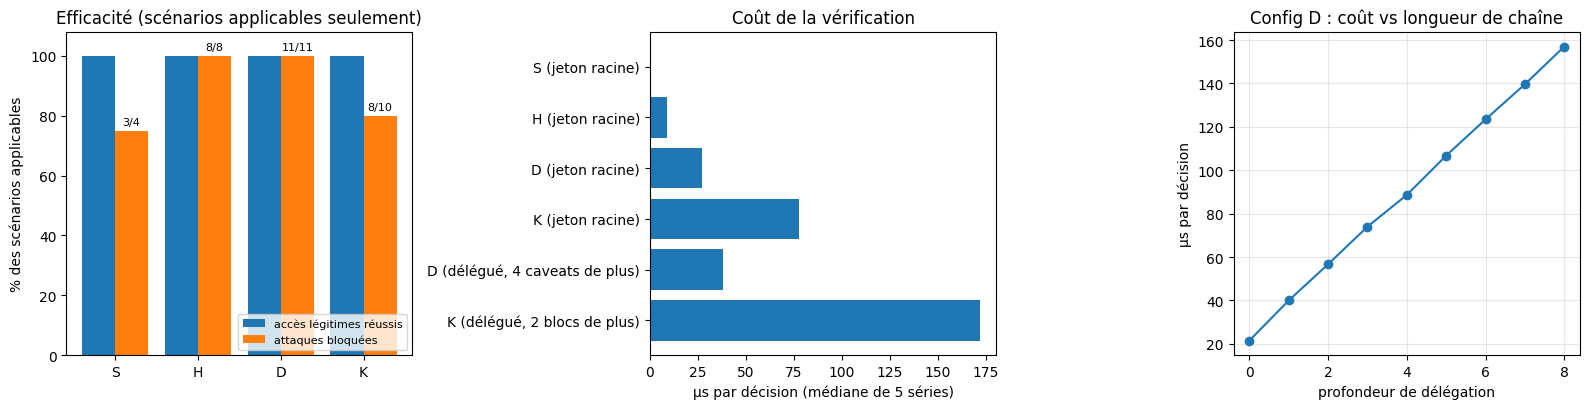

Résultats exportés dans results


In [ ]:
# ------------------------------------------------------------------
# Graphiques + export des résultats (dossier results/)
# ------------------------------------------------------------------
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    ax = axes[0]
    xs = range(len(names))
    ax.bar([x - 0.2 for x in xs], [SUMMARY[n]["legit_ok"] / SUMMARY[n]["legit_n"] * 100 for n in names], 0.4, label="accès légitimes réussis")
    ax.bar([x + 0.2 for x in xs], [SUMMARY[n]["attack_blocked"] / SUMMARY[n]["attack_n"] * 100 for n in names], 0.4, label="attaques bloquées")
    ax.set_xticks(list(xs)); ax.set_xticklabels(names); ax.set_ylim(0, 108); ax.set_ylabel("% des scénarios applicables")
    ax.set_title("Efficacité (scénarios applicables seulement)"); ax.legend(loc="lower right", fontsize=8)
    for x, n in zip(xs, names):
        ax.text(x + 0.2, SUMMARY[n]["attack_blocked"] / SUMMARY[n]["attack_n"] * 100 + 2,
                f"{SUMMARY[n]['attack_blocked']}/{SUMMARY[n]['attack_n']}", ha="center", fontsize=8)
    ax = axes[1]
    labels, vals = list(OVERHEAD), [v[0] for v in OVERHEAD.values()]
    ax.barh(labels, vals); ax.set_xlabel("µs par décision (médiane de 5 séries)"); ax.set_title("Coût de la vérification"); ax.invert_yaxis()
    ax = axes[2]
    ax.plot(list(DEPTH), list(DEPTH.values()), marker="o"); ax.set_xlabel("profondeur de délégation"); ax.set_ylabel("µs par décision")
    ax.set_title("Config D : coût vs longueur de chaîne"); ax.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(RESULTS_DIR / "secureagent_results.png", dpi=130); plt.show()
except ImportError:
    print("matplotlib absent : pip install matplotlib (graphiques non générés)")

with open(RESULTS_DIR / "secureagent_results.json", "w", encoding="utf-8") as fh:
    json.dump({"scenarios": {sid: OUTCOMES[sid] for sid, *_ in SCENARIOS}, "summary": SUMMARY,
               "overhead_us": {k: v[0] for k, v in OVERHEAD.items()}, "depth_us": DEPTH}, fh, indent=2, ensure_ascii=False)
print("Résultats exportés dans", RESULTS_DIR.resolve())


In [ ]:
# ------------------------------------------------------------------
# Constats générés à partir des mesures (rien n'est écrit « en dur »)
# ------------------------------------------------------------------
print("Constats :")
for n in names:
    wrong = [d for sid, d, k, _, _ in SCENARIOS if is_correct(k, OUTCOMES[sid][n]) is False]
    print(f" • {n} : " + ("aucun comportement incorrect sur les scénarios applicables" if not wrong else "INCORRECT sur → " + " ; ".join(wrong)))
_base = OVERHEAD["S (jeton racine)"][0]
for k, (med, _, _) in OVERHEAD.items():
    if k != "S (jeton racine)":
        print(f" • coût {k:<34} ≈ {med:6.1f} µs, soit ×{med / _base:,.0f} la vérification statique ({_base:.1f} µs)")
print(f" • Profondeur 0 → 8 (config D) : {DEPTH[0]:.1f} → {DEPTH[8]:.1f} µs")
print(f" • Workflow complet avec jetons : {metrics_cap['Temps (s)']} s, {N_RUN_DECISIONS} décisions, "
      f"{metrics_cap['Actions refusées']} refus (run nominal)")


Constats :
 • S : INCORRECT sur → « src/test/../main/… » par test_agent
 • H : aucun comportement incorrect sur les scénarios applicables
 • D : aucun comportement incorrect sur les scénarios applicables
 • K : INCORRECT sur → Jeton de code_agent rejoué par test_agent ; Fausse délégation d'un jeton volé
 • coût H (jeton racine)                   ≈    8.7 µs, soit ×14 la vérification statique (0.6 µs)
 • coût D (jeton racine)                   ≈   27.4 µs, soit ×45 la vérification statique (0.6 µs)
 • coût K (jeton racine)                   ≈   77.8 µs, soit ×128 la vérification statique (0.6 µs)
 • coût D (délégué, 4 caveats de plus)     ≈   37.9 µs, soit ×62 la vérification statique (0.6 µs)
 • coût K (délégué, 2 blocs de plus)       ≈  172.0 µs, soit ×283 la vérification statique (0.6 µs)
 • Profondeur 0 → 8 (config D) : 21.6 → 157.0 µs
 • Workflow complet avec jetons : 0.014 s, 64 décisions, 0 refus (run nominal)


## 13.8 Indépendance du domaine : actions d'un système autonome

Le moteur n'a **aucune** connaissance de Spring Boot : il raisonne sur des triplets *(agent, action, ressource)*. Pour le montrer, on remplace les outils de développement par des actions abstraites d'un système autonome (consulter l'état, lire une ressource, demander une opération) et on ajoute le caveat `needs_human` pour les opérations sensibles.

⚠️ **Ce que cette cellule démontre et ne démontre pas.** Elle démontre que *le même moteur, sans modification*, applique un mandat sur un autre domaine. Elle ne démontre **pas** une intégration avec PX4, Gazebo, ROS 2 ou un matériel : il n'y a ici aucun simulateur de vol, seulement des noms d'actions. L'étape suivante serait de brancher `request_operation` sur un simulateur logiciel.

In [ ]:
# ============================================================
# 13.8  Même moteur, domaine différent (aucune modification de AuthorizationEngine)
# ============================================================
ae = AuthorizationEngine()
ae_ids = {n: ae.register_agent(n) for n in ["supervisor", "mission_agent", "monitor_agent"]}

SENSITIVE = ["ops/critical/"]
mission_cap = ae.mint("mission_agent", {"get_status", "read_resource", "request_operation"},
                      scopes=[(["read_resource"],      ["telemetry/", "ops/"]),
                              (["request_operation"],  ["ops/survey/", "ops/critical/"])],
                      ttl=1800, human_prefixes=SENSITIVE, must_scope=("request_operation",))
monitor_cap = delegate(ae.mint("supervisor", {"get_status", "read_resource", "request_operation"},
                               scopes=[(["read_resource"], ["telemetry/"]), (["request_operation"], ["ops/"])],
                               ttl=1800, must_scope=("request_operation",)),
                       ae_ids["supervisor"], "monitor_agent", actions={"get_status", "read_resource"}, ttl=900)

def autonomous_call(agent, cap, action, resource=None):
    d = ae.verify(cap, agent, action, resource)
    if d["allow"] and d["needs_human"]:
        approved = ask_human(agent, f"Autoriser {action} sur {resource} ?")        # même mécanisme que le TP
        d = decision(approved, "OK_HUMAN" if approved else "HUMAN_REFUSED", "human", True, d["token_id"], d["chain"])
    show_decision(f"{agent}: {action}({resource or ''})", d)
    return d

_n0 = len(HUMAN_INTERVENTIONS)
r = [autonomous_call("mission_agent", mission_cap, "get_status"),
     autonomous_call("mission_agent", mission_cap, "read_resource", "telemetry/battery"),
     autonomous_call("mission_agent", mission_cap, "request_operation", "ops/survey/zone-A"),
     autonomous_call("mission_agent", mission_cap, "request_operation", "ops/critical/arm"),          # sensible : humain
     autonomous_call("mission_agent", mission_cap, "request_operation", "ops/geofence/disable"),      # hors mandat
     autonomous_call("monitor_agent", monitor_cap, "request_operation", "ops/survey/zone-A"),         # observateur : lecture seule
     autonomous_call("monitor_agent", monitor_cap, "read_resource", "telemetry/battery")]

check("Les opérations dans le mandat passent", r[0]["allow"] and r[1]["allow"] and r[2]["allow"])
check("L'opération sensible déclenche une validation humaine", len(HUMAN_INTERVENTIONS) == _n0 + 1 and r[3]["step"] == "human")
check("L'opération hors mandat est refusée", not r[4]["allow"] and r[4]["code"] == "SCOPE_VIOLATION")
check("L'observateur ne peut pas demander d'opération", not r[5]["allow"] and r[6]["allow"])


✅ AUTORISÉ mission_agent: get_status()                                OK
✅ AUTORISÉ mission_agent: read_resource(telemetry/battery)            OK
✅ AUTORISÉ mission_agent: request_operation(ops/survey/zone-A)        OK
✅ AUTORISÉ mission_agent: request_operation(ops/critical/arm)         OK_HUMAN  (validation humaine requise)
⛔ REFUSÉ   mission_agent: request_operation(ops/geofence/disable)     SCOPE_VIOLATION
⛔ REFUSÉ   monitor_agent: request_operation(ops/survey/zone-A)        ACTION_NOT_GRANTED
✅ AUTORISÉ monitor_agent: read_resource(telemetry/battery)            OK
✅ Les opérations dans le mandat passent
✅ L'opération sensible déclenche une validation humaine
✅ L'opération hors mandat est refusée
✅ L'observateur ne peut pas demander d'opération


True

## 13.9 Analyse, limites et menaces résiduelles

### Ce que les expériences montrent (et ne montrent pas)

* **Efficacité.** Sur les scénarios qui s'appliquent à une configuration, la table de 13.7 donne les comportements corrects et incorrects. Lire les ❌ avant les ✅ : ce sont eux qui indiquent où un mécanisme est insuffisant.
* **La configuration statique S n'est pas fausse, elle est *muette*.** Elle ne peut tout simplement pas répondre à plusieurs scénarios (aucun jeton à falsifier, à expirer ou à déléguer) : les « — » de la colonne S sont des **capacités absentes**, pas des succès. Et sur `path_trick`, sa comparaison de préfixes sur chaîne brute est exploitable *au niveau de la décision* ; dans le TP, elle est sauvée par `write_file` qui re-vérifie le chemin résolu, c'est-à-dire par la défense en profondeur.
* **Le jeton plat H (JWT/HS256)** résout falsification, expiration et rejeu, mais **ne délègue pas** : toute délégation exigerait que l'émetteur réémette un jeton. C'est la preuve que « JWT » est un format et non un modèle de capacités.
* **Le jeton atténuable D** ajoute la délégation monotone. La propriété « un jeton dérivé n'élargit jamais les droits » est vérifiée par un test de propriété en 13.6 (1500 chaînes aléatoires). Un test aléatoire **ne constitue pas une preuve** : il réduit la probabilité d'un bug, il ne l'élimine pas.
* **Biscuit réel (K), s'il est installé**, est un jeton **porteur** : il atténue correctement (un bloc ne peut pas ajouter de droit), mais voler le jeton suffit à l'utiliser. Une liaison au porteur exige un mécanisme en plus (par exemple une clé publique de l'agent dans le jeton et une signature de défi, non implémentée ici). Notre config D comble ce point avec des preuves de délégation signées par la clé de chaque agent : c'est un choix de conception, pas une supériorité générale de D sur Biscuit, qui offre par ailleurs un langage de politiques (Datalog) bien plus expressif.
* **Coût.** Les décisions de D et K coûtent plus cher que la vérification statique (ordre de grandeur de quelques dizaines à quelques centaines de µs contre ~1 µs), et D croît avec la longueur de chaîne. Dans ce TP, cela reste négligeable devant un appel d'outil ou de LLM ; les valeurs exactes dépendent de la machine et sont affichées en 13.7.

### Limites assumées

1. **Agents simulés** : aucun LLM. On sécurise le canal d'action ; on ne mesure pas la robustesse face à de vraies injections de prompt.
2. **Authentification de l'appelant (hypothèse H2)** : le moteur croit l'argument `agent` fourni par l'orchestrateur. Sans authentification réelle (canal authentifié, clés par agent à la présentation), un agent qui contrôle cet argument et possède un jeton volé reste dangereux.
3. **Clé racine symétrique** : celui qui vérifie peut aussi créer. Une version asymétrique (Ed25519, comme Biscuit) sépare émission et vérification.
4. **Révocation grossière** : on révoque un jeton entier (et donc toute sa descendance), pas un droit isolé ; expiration courte recommandée.
5. **Jeux de scénarios choisis par l'auteur** : 15 scénarios écrits par la même personne que celle qui a écrit les défenses. C'est un biais de confirmation connu ; un évaluateur extérieur ou un fuzzing plus large en trouverait probablement d'autres.
6. **Simulation du temps** : l'expiration est testée avec une horloge injectée, pas avec de vraies attentes.
7. **Pas de domaine physique** : voir l'avertissement en 13.8.

### Pour aller plus loin (suite logique)

Signatures asymétriques ; liaison au porteur par preuve de possession ; politiques Datalog Biscuit pour exprimer des contraintes plus riches (horaires, quotas) ; branchement d'un vrai LLM dans un agent avec `llm_complete` pour mesurer l'effet sur des tentatives d'injection réelles ; simulateur logiciel pour les actions du 13.8.

# 🚀 Pour aller plus loin

| Extension | Idée |
|---|---|
| **Mode Maven réel** | `USE_REAL_MAVEN = True` : les agents lancent vraiment `mvn clean test` ; les erreurs de compilation deviennent des `MAVEN_ERROR` |
| **Vrai LLM** | Branchez `llm_complete` dans le Code Agent : le modèle écrit/corrige le Java ; gardez `static_check`/Maven comme **juge indépendant** |
| **Agent Git** | `git status`, `git diff`, `git commit` : avec validation humaine avant tout commit |
| **Agent Security** | Secrets dans le code, dépendances vulnérables, endpoints non protégés |
| **Agent Database** | Modèle de données et migrations (Flyway) |
| **Agent API** | Analyse automatique des endpoints / génération OpenAPI |
| **Agent UI** | Génération d'une interface front |
| **Agent CI/CD** | Analyse du pipeline et propositions d'amélioration |
| **Sécurité Spring** | Ajouter Spring Security + JWT à l'API |

# 📦 Livrables du TP

1. **Architecture** : diagramme de votre système multi-agents (Partie 3 du notebook, à compléter).
2. **Notebook** : ce fichier, exécutable de bout en bout, avec les 14 cellules À FAIRE et les réponses aux 12 questions.
3. **Application Spring Boot** : votre projet `skeleton/task-manager` **complété** (Entity, Repository, Service, Controller, DTO, gestion d'erreurs, validation, tests qui passent avec `mvn clean test`).
4. **DevOps** : `Dockerfile`, pipeline CI, exécution automatique des tests, génération du package.
5. **Documentation** : un `README.md` permettant d'installer, lancer, tester, construire l'image Docker et comprendre l'architecture.

## Barème indicatif (/20)

| Critère | Points |
|---|:---:|
| Cellules À FAIRE 1 à 14 validées (✅) | 6 |
| Projet Spring Boot complété, `mvn clean test` au vert | 5 |
| Orchestration : boucle de correction, plafond, escalade humaine | 2 |
| Sécurité : moindre privilège, validation humaine, journal exploité | 2 |
| Comparaison A/B/C : mesures et analyse | 2 |
| Réponses aux questions de réflexion | 2 |
| DevOps (Docker + CI) et documentation | 1 |